# Signature detection using official YOLOX-Tiny

A single-class, end-to-end pipeline for the three requested Roboflow projects. Notebook authoring and revisions do not execute its pipeline. Saved outputs from unchanged cells belong to your own runs; changed cells must be rerun.

Run in a fresh **Google Colab GPU runtime** (Runtime → Change runtime type → GPU), or your existing local CUDA GPU environment. Configure the next cell, then execute cells in order. All three datasets are read from the existing `Datasets/` folder; no dataset download code or Roboflow API key is needed. Environment setup still installs dependencies and obtains official YOLOX source and pretrained weights when **you** run it. **Training and evaluation are now enabled by default:** executing all cells trains YOLOX-Tiny and then evaluates the best checkpoint. Set either switch to `False` to skip that stage. Retain the project directory or copy it to Drive before your Colab session ends.

The model uses YOLOX-Tiny depth `0.33`, width `0.375`, and a one-class head. Normalized YOLO TXT is provided as an intermediate/reusable export; the official trainer reads the final **COCO JSON**, not YOLO TXT. All output class indices are `0`; the COCO category ID is `1`, mapped internally by YOLOX to index `0`.

## Evidence used to design the import
Read-only inspection of the existing workspace exports on **2026-11-03** found the following structures and category metadata. These are schema observations, not claims that the datasets have been cleaned or validated.

| Requested project | Selected version | Observed export | Category metadata |
|---|---:|---|---|
| [lukasz-bondaruk/signature-yolo](https://universe.roboflow.com/lukasz-bondaruk/signature-yolo) | 6 | `train/`, `valid/`; split-level `_annotations.coco.json` | IDs 0 and 1 named `signatures` |
| [tech-ysdkk/signature-detection-hlx8j](https://universe.roboflow.com/tech-ysdkk/signature-detection-hlx8j) | 3 | `train/`, `valid/`, `test/`; split-level COCO JSON | IDs 0 and 1 named `signature` |
| [rf100-vl/signatures-xc8up-ytnch-qzw1d-pmbl](https://universe.roboflow.com/rf100-vl/signatures-xc8up-ytnch-qzw1d-pmbl) | 1 | `train/`, `valid/`, `test/`; split-level COCO JSON | ID 0 named after the project; ID 1 named `signature` |

The importer re-detects the actual JSON schema and used category IDs for each export at runtime. It maps only `signature` and `signatures`, after case/whitespace normalization. An unused parent category is reported without becoming a detection class; an unknown **used** category stops the pipeline. Other export formats are identified and rejected with instructions to obtain COCO, avoiding guessed conversions.

The tech project describes Tobacco800/RF100 overlap, and its local README describes offline augmentations. Original split membership is therefore discarded and recorded as provenance. Exact content, source filename families, PDF document families, rotation-aware perceptual similarity, and optional manual origin groups are joined **before** creating new splits.

## Assumptions and limits

- COCO images with zero annotations are retained as declared negatives by default. This assumes exhaustive labeling; set `KEEP_DECLARED_NEGATIVES=False` if that assumption is unsuitable. Unreferenced files are never assumed to be negatives.
- Raw inputs are never modified or deleted. Invalid images/labels are quarantined by manifest; small boundary overshoots can be clipped with an audit entry. Conflicting annotations on identical pixels require an explicit resolution.
- Perceptual matching is a heuristic: arbitrary crops, heavy edits, and unrelated filenames may evade it; visually similar forms may be grouped conservatively. The audit guarantees separation of **detected** families, not proof of absence of every semantic duplicate. Review pair montages and supply manual origin groups where needed.
- Approximate 80:10:10 splitting respects whole families, so exact ratios and source stratification may be impossible. No published benchmark split is preserved.
- Native image dimensions are retained; YOLOX resizes and pads while preserving aspect ratio. Existing stretch resize/augmentation in a Roboflow version cannot be undone. Tiny signatures may benefit from 640 or 832 input sizes; assess this on validation data.
- Colab supplies its matched CUDA PyTorch/torchvision pair. This notebook checks that pair instead of replacing GPU wheels. Library ranges and a runtime lock report are included; no environment has been experimentally certified here. Use a fresh runtime if pip asks for a restart.
- Review the original dataset licenses/attributions before use or redistribution. The tech workspace README lists an undefined license while its public description states Apache 2.0; resolve that discrepancy with the owner for your intended use.


## Stage 1 — Environment and configuration

Edit the paths and switches here. By default, `LOCAL_DATASET_BASE` points to `Datasets/` under the notebook kernel's working directory, matching this project's existing layout. You can set `SIGNATURE_DATASET_BASE` in the environment or edit `LOCAL_DATASET_BASE` to use an absolute path. Each source's `local_dir` can also be set explicitly. Missing folders cause a clear error; the notebook never downloads datasets.

For Google Colab, make the existing `Datasets/` folder available through mounted Google Drive or upload it yourself, then set `LOCAL_DATASET_BASE` to its Colab path. A Colab runtime cannot directly access a Windows `D:` drive. No Roboflow SDK, API credentials, or Colab Secrets are required. `RUN_TRAINING=True` launches training when you reach Stage 8; `RUN_EVALUATION=True` evaluates the best trained checkpoint in Stage 9. Both are enabled below. Review the generated audit reports before reaching training.


In [23]:
from pathlib import Path
import os, sys, json, hashlib, random, subprocess, shutil, zipfile, re, math, io, contextlib
from collections import Counter, defaultdict
from datetime import datetime, timezone
from urllib.request import urlopen, Request

PROJECT_ROOT = Path(os.getenv('SIGNATURE_PROJECT_ROOT', '/content/signature_yolox' if Path('/content').exists() else './signature_yolox')).expanduser().resolve()
LOCAL_DATASET_BASE = Path(os.getenv('SIGNATURE_DATASET_BASE', './Datasets')).expanduser().resolve()
SEED = 42
RUN_TRAINING = True   # Stage 8 runs the official trainer when you execute that cell.
RUN_EVALUATION = True # Stage 9 evaluates the best checkpoint after training finishes.
ACCEPT_QUARANTINE = False  # After inspecting audit.csv, allow training with reported exclusions.
KEEP_DECLARED_NEGATIVES = True
CLIP_TOLERANCE_PX = 2.0  # Larger excursions quarantine the whole image.
PHASH_DISTANCE = 6       # Candidate radius; visual verification is required before grouping.
MAX_GROUP_FRACTION = 0.25  # Stop for review if similarity creates a giant component.
SPLIT_RATIOS = {'train': 0.8, 'val': 0.1, 'test': 0.1}
MANUAL_GROUPS_CSV = None  # Optional Path: columns source,relative_path,group (shared across sources).
DUPLICATE_CHOICES_JSON = None  # Optional Path: pixel SHA256 -> uid of authoritative annotation.
YOLOX_TAG = '0.3.0'
SOURCE_SHA256 = None  # Optionally enforce a previously recorded source archive digest.
WEIGHTS_SHA256 = None  # Optionally enforce a previously recorded official weights digest.
AUTO_SELECT_BATCH_SIZE = True  # Stage 7 benchmarks batches 8 and 16 when you execute it.
FORCE_FULL_VALIDATION = False  # Reuse the successful validation of unchanged prepared files.
TRAIN = dict(input_size=416, batch_size=8, epochs=30, learning_rate=0.00125,
             optimizer='SGD', momentum=0.9, weight_decay=5e-4, workers=2,
             warmup_epochs=3, no_aug_epochs=5, eval_interval=5, fp16=True, fast_cudnn=True,
             mosaic_prob=0.5, mosaic_scale=[0.5, 1.5], enable_mixup=False,
             flip_prob=0.0, hsv_prob=0.2, degrees=5.0, shear=1.0, translate=0.05,
             multiscale_range=0, max_labels=300, test_conf=0.001, nms=0.65,
             save_history_ckpt=False, experiment='signature_yolox_tiny',
             resume=True, resume_checkpoint=None)  # Continue latest_ckpt.pth; 30 is the TOTAL epoch target.
EVAL = dict(split='test', confidence=0.25, match_iou=0.5, max_detections=100,
            checkpoint=None, samples=6)  # None selects best_ckpt.pth.
SOURCES = [
    dict(key='bondaruk', workspace='lukasz-bondaruk', project='signature-yolo', version=6,
         local_dir=LOCAL_DATASET_BASE / 'signature-yolo.v6i.coco'),
    dict(key='tech', workspace='tech-ysdkk', project='signature-detection-hlx8j', version=3,
         local_dir=LOCAL_DATASET_BASE / 'Signature Detection.v3i.coco'),
    dict(key='rf100', workspace='rf100-vl', project='signatures-xc8up-ytnch-qzw1d-pmbl', version=1,
         local_dir=LOCAL_DATASET_BASE / 'signatures-xc8up-ytnch-qzw1d-pmbl.v1i.coco'),
]
REPORTS = PROJECT_ROOT / 'reports'
CLEAN = PROJECT_ROOT / 'clean_yolo'
MERGED = PROJECT_ROOT / 'merged_coco'
YOLOX_ROOT = PROJECT_ROOT / f'YOLOX-{YOLOX_TAG}'
WEIGHTS = PROJECT_ROOT / 'weights'
OUTPUTS = PROJECT_ROOT / 'outputs'
for directory in (PROJECT_ROOT, REPORTS, CLEAN, MERGED, WEIGHTS, OUTPUTS):
    directory.mkdir(parents=True, exist_ok=True)
assert abs(sum(SPLIT_RATIOS.values()) - 1) < 1e-9 and all(v > 0 for v in SPLIT_RATIOS.values())
assert TRAIN['optimizer'] == 'SGD', 'The official optimizer here is SGD with Nesterov momentum.'
assert TRAIN['input_size'] >= 128 and TRAIN['input_size'] % 32 == 0
assert TRAIN['batch_size'] >= 2 and TRAIN['epochs'] > TRAIN['warmup_epochs'] + TRAIN['no_aug_epochs']
assert 0 <= PHASH_DISTANCE <= 16
print('Project:', PROJECT_ROOT)


Project: D:\Navtcc\Internship\Signature Identifier\signature_yolox


In [2]:
# Do not install the old YOLOX requirements.txt: it includes obsolete ONNX pins.
# Pure Python source loading below avoids an unnecessary C++ extension build.
packages = ['numpy>=1.26,<2.3', 'Pillow>=10,<13', 'pandas>=2.2,<3',
            'matplotlib>=3.8,<4', 'opencv-python-headless>=4.10,<5',
            'pycocotools>=2.0.8,<3', 'ImageHash==4.3.2', 'loguru>=0.7,<0.8',
            'thop==0.1.1.post2209072238', 'tabulate==0.9.0', 'tqdm>=4.66,<5',
            'tensorboard>=2.16,<3']
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', *packages], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
import imagehash, cv2, torch, torchvision
from tqdm.auto import tqdm
from IPython.display import display
from importlib.metadata import version
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

assert tuple(map(int, torch.__version__.split('+')[0].split('.')[:2])) >= (2, 1)
# This fails early if torch and torchvision have incompatible binary operators.
torchvision.ops.nms(torch.tensor([[0., 0., 5., 5.]]), torch.tensor([0.9]), 0.5)
if torch.cuda.is_available():
    torchvision.ops.nms(torch.tensor([[0., 0., 5., 5.]], device='cuda'),
                        torch.tensor([0.9], device='cuda'), 0.5)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
versions = {name: version(name) for name in ['torch', 'torchvision', 'numpy', 'Pillow',
            'pycocotools', 'ImageHash', 'opencv-python-headless', 'pandas']}
versions.update(python=sys.version, cuda=torch.version.cuda,
                gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
print(json.dumps(versions, indent=2))
(REPORTS / 'environment.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
(REPORTS / 'requirements-runtime.txt').write_text(freeze, encoding='utf-8')
if not torch.cuda.is_available():
    print('CPU preparation/evaluation is available; official training requires a CUDA GPU.')


c:\Users\syeda\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "torch": "2.14.1+cu126",
  "torchvision": "0.29.1+cu126",
  "numpy": "2.2.6",
  "Pillow": "12.3.0",
  "pycocotools": "2.0.11",
  "ImageHash": "4.3.2",
  "opencv-python-headless": "4.14.0.94",
  "pandas": "2.3.3",
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "cuda": "12.6",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU"
}


### Official source archive and compatibility

The next cell fetches the official tagged ZIP without Git and uses it directly through `PYTHONPATH`. Two small, recorded compatibility edits affect infrastructure only: use standard `pycocotools` evaluation instead of compiling the optional fast evaluator, and make the official trainer's trusted checkpoint loading explicit for modern PyTorch. The architecture, losses, optimizer, augmentation, and training loop remain official. Only load checkpoints from the official URL below or your own training runs: full checkpoint loading uses Python pickle. Archive/weight hashes and patch hashes are recorded for repeat runs. Set the optional expected digests to enforce previously observed bytes.


In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    def safe(item):
        # Preserve invalid numeric evidence in reports without emitting invalid JSON.
        if isinstance(item, float) and not math.isfinite(item):
            return f'NONFINITE:{item}'
        if isinstance(item, dict):
            return {key: safe(val) for key, val in item.items()}
        if isinstance(item, (list, tuple)):
            return [safe(val) for val in item]
        return item
    temporary.write_text(json.dumps(safe(value), indent=2, default=str, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def download_file(url, target, expected_sha=None):
    target = Path(target)
    if not target.exists():
        temporary = target.with_suffix(target.suffix + '.part')
        try:
            request = Request(url, headers={'User-Agent': 'Signature-YOLOX-Notebook'})
            with urlopen(request, timeout=180) as response, temporary.open('wb') as stream:
                shutil.copyfileobj(response, stream)
            if not temporary.stat().st_size:
                raise RuntimeError('The download was empty.')
            temporary.replace(target)
        except Exception:
            temporary.unlink(missing_ok=True)
            raise
    digest = sha256_file(target)
    if expected_sha and digest != expected_sha:
        raise RuntimeError(f'Hash mismatch for {target.name}; keep it for inspection and correct the file.')
    return digest

archive = PROJECT_ROOT / f'YOLOX-{YOLOX_TAG}.zip'
source_url = f'https://codeload.github.com/Megvii-BaseDetection/YOLOX/zip/refs/tags/{YOLOX_TAG}'
archive_sha = download_file(source_url, archive, SOURCE_SHA256)
if not YOLOX_ROOT.exists():
    with zipfile.ZipFile(archive) as bundle:
        for member in bundle.infolist():
            resolved = (PROJECT_ROOT / member.filename).resolve()
            if not resolved.is_relative_to(PROJECT_ROOT):
                raise RuntimeError('Unsafe archive path.')
        bundle.extractall(PROJECT_ROOT)
assert (YOLOX_ROOT / 'yolox' / 'exp' / 'yolox_base.py').is_file(), 'Incomplete source extraction.'
patches = []
def patch_exact(relative, before, after, count):
    path = YOLOX_ROOT / relative
    text = path.read_text(encoding='utf-8')
    if text.count(before) == count:
        original = hashlib.sha256(text.encode()).hexdigest()
        text = text.replace(before, after)
        path.write_text(text, encoding='utf-8')
    elif text.count(after) == count:
        original = 'already patched'
    else:
        raise RuntimeError(f'Unexpected source version in {relative}; inspect instead of patching blindly.')
    patches.append(dict(file=relative, original=original, modified=sha256_file(path)))

patch_exact('yolox/evaluators/coco_evaluator.py',
            'from yolox.layers import COCOeval_opt as COCOeval',
            'from pycocotools.cocoeval import COCOeval  # standard evaluator', 1)
patch_exact('yolox/core/trainer.py',
            'torch.load(ckpt_file, map_location=self.device)',
            'torch.load(ckpt_file, map_location=self.device, weights_only=False)', 2)
sys.path.insert(0, str(YOLOX_ROOT))
os.environ['PYTHONPATH'] = str(YOLOX_ROOT) + os.pathsep + os.environ.get('PYTHONPATH', '')
import yolox
assert Path(yolox.__file__).resolve().is_relative_to(YOLOX_ROOT)
write_json(REPORTS / 'source_manifest.json', dict(tag=YOLOX_TAG, url=source_url,
           archive_sha256=archive_sha, patches=patches, yolox_version=yolox.__version__))
print('Official YOLOX source:', yolox.__version__, Path(yolox.__file__).resolve())


Official YOLOX source: 0.3.0 D:\Navtcc\Internship\Signature Identifier\signature_yolox\YOLOX-0.3.0\yolox\__init__.py


## Stage 2 — Locate the three existing local datasets

Use the COCO exports already present in `Datasets/`. This cell resolves and checks all three configured directories, then records their paths and project/version provenance. No dataset is downloaded, copied, or modified here. A missing or incorrect directory stops processing instead of skipping a required source. The next stage verifies actual annotation structures and class mappings.

Expected existing layout:
```text
Datasets/
  signature-yolo.v6i.coco/
    train/<images> + _annotations.coco.json
    valid/<images> + _annotations.coco.json
  Signature Detection.v3i.coco/
    train/<images> + _annotations.coco.json
    valid/<images> + _annotations.coco.json
    test/<images>  + _annotations.coco.json
  signatures-xc8up-ytnch-qzw1d-pmbl.v1i.coco/
    train/<images> + _annotations.coco.json
    valid/<images> + _annotations.coco.json
    test/<images>  + _annotations.coco.json
```

Original README files remain in each dataset folder for attribution and preprocessing provenance. The configured workspace/project names are descriptive metadata only; no Roboflow service is contacted.


In [4]:
source_roots, missing_sources = {}, []
for spec in SOURCES:
    root = Path(spec['local_dir']).expanduser().resolve()
    if not root.is_dir():
        missing_sources.append(dict(source=spec['key'], expected_directory=str(root)))
        continue
    source_roots[spec['key']] = root
    print(spec['key'], '->', root)
if missing_sources:
    write_json(REPORTS / 'missing_local_datasets.json', missing_sources)
    raise FileNotFoundError('Required local dataset folders are missing. Set LOCAL_DATASET_BASE or each source local_dir to the existing exports: ' + json.dumps(missing_sources))
assert set(source_roots) == {spec['key'] for spec in SOURCES}
assert len(set(source_roots.values())) == len(SOURCES), 'Each source must reference its own dataset directory.'
write_json(REPORTS / 'local_datasets.json', [dict(**spec, resolved_root=source_roots[spec['key']]) for spec in SOURCES])


bondaruk -> D:\Navtcc\Internship\Signature Identifier\Datasets\signature-yolo.v6i.coco
tech -> D:\Navtcc\Internship\Signature Identifier\Datasets\Signature Detection.v3i.coco
rf100 -> D:\Navtcc\Internship\Signature Identifier\Datasets\signatures-xc8up-ytnch-qzw1d-pmbl.v1i.coco


## Stage 3 — Inspect actual schemas, images, and annotations

Each JSON is checked for COCO's `images`, `annotations`, and `categories` arrays. Category names/IDs and used IDs are printed per file, including unused parent entries. Duplicate IDs, dangling image references, and unknown used categories stop processing after writing a structural report. Missing split annotation files are detected by the corresponding images becoming unreferenced.

The scan reads every referenced image, verifies full decoding with Pillow and OpenCV, checks dimensions, format and EXIF orientation, and computes file/pixel hashes and pHashes for four rotations. No pixels or annotations are changed here. COCO uses one annotation file for many images: a missing per-image TXT is not an error in that source format. Images listed in COCO with no boxes are distinguished from files absent from COCO entirely. All measured counts and plots are generated only when these cells run.


In [5]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
CLASS_ALIASES = {'signature', 'signatures'}
audit, structural, raw_records, schema_rows = [], [], [], []
def record_event(source, item, action, reason, **details):
    audit.append(dict(source=source, item=str(item), action=action, reason=reason, **details))

def flush_audit():
    write_json(REPORTS / 'audit.json', audit)
    pd.DataFrame(audit, columns=sorted(set().union(*(r.keys() for r in audit))) if audit else
                 ['source', 'item', 'action', 'reason']).to_csv(REPORTS / 'audit.csv', index=False)

def unique_ids(rows, label, context):
    ids = [row.get('id') for row in rows]
    if any(not isinstance(value, int) for value in ids) or len(ids) != len(set(ids)):
        structural.append(dict(file=str(context), error=f'Non-integer, missing, or duplicate {label} IDs'))

def resolve_image(root, annotation_file, filename):
    name = Path(str(filename).replace('\\', '/'))
    if name.is_absolute() or '..' in name.parts:
        raise ValueError('Unsafe image filename')
    candidates = {p.resolve() for p in (annotation_file.parent / name,
                  annotation_file.parent / 'images' / name, root / name)
                  if p.is_file() and p.resolve().is_relative_to(root)}
    if len(candidates) > 1:
        raise ValueError('Ambiguous image filename')
    return next(iter(candidates)) if candidates else (annotation_file.parent / name).resolve()

for source, root in source_roots.items():
    referenced = set()
    coco_files = []
    for path in sorted(root.rglob('*.json')):
        if path.name.startswith('.'):
            continue
        try:
            payload = json.loads(path.read_text(encoding='utf-8-sig'))
        except (ValueError, OSError) as error:
            structural.append(dict(file=str(path), error=f'Unreadable JSON: {type(error).__name__}'))
            continue
        if isinstance(payload, dict) and {'images', 'annotations', 'categories'} <= payload.keys():
            coco_files.append((path, payload))
    if not coco_files:
        detected = 'YOLO YAML/TXT' if list(root.rglob('*.yaml')) or list(root.rglob('*.yml')) else ('VOC XML' if list(root.rglob('*.xml')) else 'unknown')
        structural.append(dict(file=str(root), error=f'Found {detected}, not COCO detection JSON. Re-export this version as coco.'))
    for path, data in coco_files:
        if not all(isinstance(data[k], list) and all(isinstance(v, dict) for v in data[k]) for k in ('images', 'annotations', 'categories')):
            structural.append(dict(file=str(path), error='COCO arrays must contain objects'))
            continue
        for key in ('images', 'annotations', 'categories'):
            unique_ids(data[key], key, path)
        categories = {c.get('id'): str(c.get('name', '')).strip().casefold() for c in data['categories']}
        used = Counter(a.get('category_id') for a in data['annotations'])
        unknown = [cid for cid in used if categories.get(cid) not in CLASS_ALIASES]
        if unknown:
            structural.append(dict(file=str(path), error=f'Unmapped USED categories: {unknown}', categories=categories))
        schema_rows.append(dict(source=source, annotation=str(path.relative_to(root)), format='COCO bbox xywh pixels',
                                images=len(data['images']), boxes=len(data['annotations']), categories=categories, used_ids=dict(used)))
        images = {im.get('id'): im for im in data['images']}
        by_image = defaultdict(list)
        for annotation in data['annotations']:
            if annotation.get('image_id') not in images:
                structural.append(dict(file=str(path), error='Dangling annotation image_id', annotation=annotation))
            by_image[annotation.get('image_id')].append(annotation)
        for im in data['images']:
            try:
                image_path = resolve_image(root, path, im['file_name'])
            except (ValueError, KeyError) as error:
                structural.append(dict(file=str(path), error=str(error), image=im))
                continue
            if image_path in referenced:
                structural.append(dict(file=str(path), error='Same path registered multiple times', path=str(image_path)))
            referenced.add(image_path)
            relative = str(image_path.relative_to(root)).replace('\\', '/')
            uid = hashlib.sha256(f'{source}:{relative}'.encode()).hexdigest()[:24]
            raw_records.append(dict(uid=uid, source=source, path=str(image_path), relative_path=relative,
                original_split=path.parent.name, annotation_file=str(path), image_metadata=im,
                original_name=(im['extra'].get('name') or im['file_name']) if isinstance(im.get('extra'), dict) else im['file_name'],
                annotations=by_image[im['id']]))
        record_event(source, path, 'inspect', 'category_mapping', categories=categories, used_ids=dict(used))
    for image_path in sorted(p for p in root.rglob('*') if p.suffix.lower() in IMAGE_SUFFIXES and p.is_file()):
        if image_path.resolve() not in referenced:
            record_event(source, image_path, 'quarantine', 'image_not_registered_in_COCO_or_missing_split_annotation')
write_json(REPORTS / 'structural_errors.json', structural)
write_json(REPORTS / 'schemas.json', schema_rows)
flush_audit()
display(pd.DataFrame(schema_rows))
if structural:
    raise RuntimeError('Structural problems found. Inspect reports/structural_errors.json and fix the export/configuration before continuing.')
assert raw_records and len({r['uid'] for r in raw_records}) == len(raw_records)


,source,annotation,format,images,boxes,categories,used_ids
0,bondaruk,train\_annotations.coco.json,COCO bbox xywh pixels,750,4088,"{0: 'signatures', 1: 'signatures'}",{1: 4088}
1,bondaruk,valid\_annotations.coco.json,COCO bbox xywh pixels,60,60,"{0: 'signatures', 1: 'signatures'}",{1: 60}
2,tech,test\_annotations.coco.json,COCO bbox xywh pixels,419,467,"{0: 'signature', 1: 'signature'}",{1: 467}
3,tech,train\_annotations.coco.json,COCO bbox xywh pixels,1980,2330,"{0: 'signature', 1: 'signature'}",{1: 2330}
4,tech,valid\_annotations.coco.json,COCO bbox xywh pixels,420,455,"{0: 'signature', 1: 'signature'}",{1: 455}
5,rf100,test\_annotations.coco.json,COCO bbox xywh pixels,35,47,"{0: 'signatures-xc8up-ytnch-qzw1d-pmbl', 1: 's...",{1: 47}
6,rf100,train\_annotations.coco.json,COCO bbox xywh pixels,238,323,"{0: 'signatures-xc8up-ytnch-qzw1d-pmbl', 1: 's...",{1: 323}
7,rf100,valid\_annotations.coco.json,COCO bbox xywh pixels,68,89,"{0: 'signatures-xc8up-ytnch-qzw1d-pmbl', 1: 's...",{1: 89}


Inspecting images (read only): 100%|██████████| 3970/3970 [03:30<00:00, 18.90it/s]


,images,boxes,unreadable_or_mismatched,declared_negatives
source,,,,
bondaruk,810,4148,0,56
rf100,341,459,0,0
tech,2819,3252,0,260


,source,format,images
0,bondaruk,JPEG,810
1,rf100,JPEG,341
2,tech,JPEG,2819


file_sha256 duplicate member files: 0
pixel_sha256 duplicate member files: 0


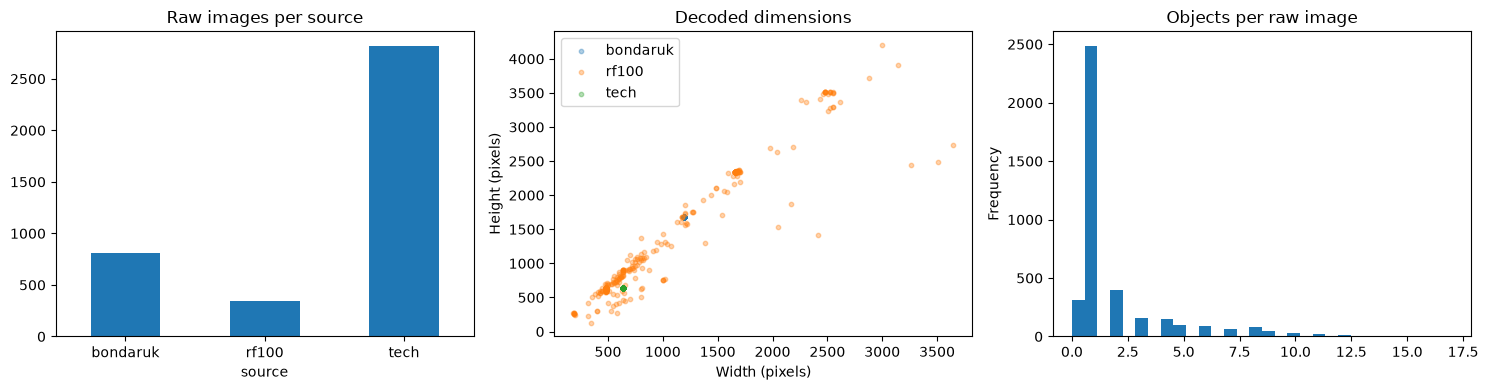

In [6]:
def inspect_pixels(record):
    path = Path(record['path'])
    if not path.is_file():
        return dict(image_error='missing_image')
    try:
        with Image.open(path) as probe:
            probe.verify()
        with Image.open(path) as image:
            image.load()
            w, h = image.size
            fmt, mode = image.format, image.mode
            orientation = image.getexif().get(274, 1)
            if getattr(image, 'n_frames', 1) != 1:
                return dict(image_error='multiframe_image_ambiguous')
            rgb = image.convert('RGB')
            pixel_sha = hashlib.sha256(f'{w}x{h}:RGB:'.encode() + rgb.tobytes()).hexdigest()
            hashes = [int(str(imagehash.phash(rgb.rotate(angle, expand=True), hash_size=8)), 16)
                      for angle in (0, 90, 180, 270)]
        decoded = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
        if decoded is None or decoded.shape[:2] != (h, w):
            return dict(image_error='opencv_decode_failed_or_size_mismatch')
        meta = record['image_metadata']
        error = None
        if orientation not in (None, 1):
            error = 'EXIF_orientation_requires_joint_pixel_and_box_review'
        elif (meta.get('width'), meta.get('height')) != (w, h):
            error = 'COCO_size_differs_from_decoded_pixels'
        return dict(width=w, height=h, format=fmt, mode=mode, orientation=orientation,
                    file_sha256=sha256_file(path), pixel_sha256=pixel_sha, phashes=hashes, image_error=error)
    except Exception as error:
        return dict(image_error=f'corrupt_or_unreadable:{type(error).__name__}')

for record in tqdm(raw_records, desc='Inspecting images (read only)'):
    record.update(inspect_pixels(record))
inventory = pd.DataFrame([{k: r.get(k) for k in ('uid', 'source', 'relative_path', 'original_split',
    'width', 'height', 'format', 'mode', 'image_error', 'file_sha256', 'pixel_sha256')} |
    {'raw_boxes': len(r['annotations'])} for r in raw_records])
inventory.to_csv(REPORTS / 'raw_inventory.csv', index=False)
display(inventory.groupby('source').agg(images=('uid', 'size'), boxes=('raw_boxes', 'sum'),
        unreadable_or_mismatched=('image_error', lambda s: int(s.notna().sum())),
        declared_negatives=('raw_boxes', lambda s: int((s == 0).sum()))))
display(inventory.groupby(['source', 'format'], dropna=False).size().rename('images').reset_index())
for column in ('file_sha256', 'pixel_sha256'):
    duplicates = inventory[inventory[column].notna() & inventory.duplicated(column, keep=False)]
    duplicates.to_csv(REPORTS / f'raw_duplicates_{column}.csv', index=False)
    print(column, 'duplicate member files:', len(duplicates))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
inventory.groupby('source').size().plot.bar(ax=axes[0], title='Raw images per source', rot=0)
for source, group in inventory.groupby('source'):
    axes[1].scatter(group['width'], group['height'], label=source, alpha=0.35, s=10)
axes[1].set(xlabel='Width (pixels)', ylabel='Height (pixels)', title='Decoded dimensions'); axes[1].legend()
inventory['raw_boxes'].plot.hist(bins=30, ax=axes[2], title='Objects per raw image')
fig.tight_layout(); fig.savefig(REPORTS / 'raw_statistics.png', dpi=150); plt.show()


## Stage 4 — Clean labels and normalize classes

All clean boxes are stored as floating-point pixel `xyxy`; the reusable TXT export uses `0 cx cy width height`, normalized by each image's actual dimensions. Only boundary excursions within `CLIP_TOLERANCE_PX` are repaired. Non-finite, zero-area, negative-size, largely out-of-bounds, or crowd boxes quarantine the **entire image**, retaining its raw data and valid proposed boxes in a review manifest. This prevents a discarded bad box from becoming an unlabeled signature in training. No size-based removal of small signatures is performed.

Exact file/pixel duplicates are collapsed to one lossless RGB image only when their box sets agree at six decimal places. Conflicts are saved to `duplicate_conflicts.json` and stop processing. Resolve the source labels or create a JSON object mapping a conflict's full pixel SHA256 to the chosen authoritative `uid`, set `DUPLICATE_CHOICES_JSON`, and rerun from this stage. All member provenance and the chosen annotation remain recorded. Near duplicates retain their own labels and pixels.


In [7]:
# Reset stage-specific audit entries to make rerunning this stage reproducible.
audit = [r for r in audit if r['reason'] in ('category_mapping', 'image_not_registered_in_COCO_or_missing_split_annotation')]
clean_records, quarantined = [], []
def clean_box(annotation, width, height):
    if annotation.get('iscrowd', 0) != 0:
        raise ValueError('crowd_annotation_requires_review')
    box = np.asarray(annotation.get('bbox', []), dtype=float)
    if box.shape != (4,) or not np.isfinite(box).all():
        raise ValueError('bbox_must_have_four_finite_values')
    x, y, w, h = box.tolist()
    if w <= 0 or h <= 0:
        raise ValueError('nonpositive_bbox_size')
    original = np.array([x, y, x + w, y + h], dtype=float)
    clipped = np.clip(original, [0, 0, 0, 0], [width, height, width, height])
    if np.max(np.abs(original - clipped)) > CLIP_TOLERANCE_PX:
        raise ValueError('bbox_outside_image_beyond_tolerance')
    if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
        raise ValueError('bbox_has_no_area_inside_image')
    return clipped.tolist(), not np.array_equal(original, clipped)

for record in raw_records:
    errors, boxes = [], []
    if record['image_error']:
        errors.append(record['image_error'])
    else:
        for annotation in record['annotations']:
            try:
                box, clipped = clean_box(annotation, record['width'], record['height'])
                boxes.append(box)
                if clipped:
                    record_event(record['source'], record['path'], 'repair', 'clip_minor_boundary_overshoot',
                                 annotation_id=annotation['id'], before=annotation['bbox'], after=box)
                area = (box[2] - box[0]) * (box[3] - box[1])
                if annotation.get('area') != area:
                    record_event(record['source'], record['path'], 'repair', 'recompute_bbox_area',
                                 annotation_id=annotation['id'], before=annotation.get('area'), after=area)
            except (ValueError, TypeError, OverflowError) as error:
                errors.append(str(error))
                record_event(record['source'], record['path'], 'invalid_annotation', str(error), annotation=annotation)
        unique = {tuple(round(v, 6) for v in box): box for box in boxes}
        if len(unique) < len(boxes):
            record_event(record['source'], record['path'], 'repair', 'remove_repeated_identical_boxes',
                         count=len(boxes) - len(unique))
        boxes = [unique[key] for key in sorted(unique)]
        if not boxes and not record['annotations'] and not KEEP_DECLARED_NEGATIVES:
            errors.append('declared_negative_requires_review')
    if errors:
        record_event(record['source'], record['path'], 'quarantine', ';'.join(sorted(set(errors))), uid=record['uid'])
        quarantined.append(dict(**record, proposed_boxes=boxes, reasons=errors))
    else:
        provenance = {k: record[k] for k in ('uid', 'source', 'relative_path', 'original_split',
                      'annotation_file', 'original_name', 'file_sha256')}
        clean_records.append(dict(**record, boxes=boxes, members=[provenance]))
write_json(REPORTS / 'quarantined_records.json', quarantined)
flush_audit()
display(pd.DataFrame([dict(source=s, input_images=sum(r['source'] == s for r in raw_records),
        eligible_images=sum(r['source'] == s for r in clean_records),
        quarantined_images=sum(r['source'] == s for r in quarantined)) for s in source_roots]))
assert all(any(r['source'] == source for r in clean_records) for source in source_roots), 'A source has no usable images. Review the quarantine report.'
assert clean_records


,source,input_images,eligible_images,quarantined_images
0,bondaruk,810,810,0
1,tech,2819,2819,0
2,rf100,341,341,0


In [8]:
choices = json.loads(Path(DUPLICATE_CHOICES_JSON).read_text()) if DUPLICATE_CHOICES_JSON else {}
pixel_groups = defaultdict(list)
for record in clean_records:
    pixel_groups[record['pixel_sha256']].append(record)
unique_records, conflicts = [], []
for digest, members in sorted(pixel_groups.items()):
    members = sorted(members, key=lambda r: r['uid'])
    signatures = {tuple(tuple(round(v, 6) for v in box) for box in r['boxes']) for r in members}
    if len(signatures) > 1:
        selected = choices.get(digest)
        if selected not in {r['uid'] for r in members}:
            conflicts.append(dict(pixel_sha256=digest, members=[
                {k: r[k] for k in ('uid', 'source', 'path', 'boxes')} for r in members]))
            continue
        representative = next(r for r in members if r['uid'] == selected).copy()
        record_event(representative['source'], representative['path'], 'resolve',
                     'manual_duplicate_annotation_choice', pixel_sha256=digest, uid=selected)
    else:
        representative = members[0].copy()
    representative['members'] = [p for r in members for p in r['members']]
    unique_records.append(representative)
    for duplicate in members:
        if duplicate['uid'] != representative['uid']:
            record_event(duplicate['source'], duplicate['path'], 'deduplicate', 'identical_RGB_pixels',
                         kept_uid=representative['uid'], removed_uid=duplicate['uid'], pixel_sha256=digest)
write_json(REPORTS / 'duplicate_conflicts.json', conflicts)
flush_audit()
if conflicts:
    raise RuntimeError('Identical images have conflicting annotations. Review duplicate_conflicts.json and provide an explicit choice; no arbitrary union or label loss is applied.')
assert len({r['pixel_sha256'] for r in unique_records}) == len(unique_records)
print('Eligible files:', len(clean_records), '| unique pixel images:', len(unique_records))

def normalized_boxes(record):
    w, h = record['width'], record['height']
    return [[(x1 + x2) / (2*w), (y1 + y2) / (2*h), (x2-x1)/w, (y2-y1)/h]
            for x1, y1, x2, y2 in record['boxes']]

(CLEAN / 'images').mkdir(exist_ok=True); (CLEAN / 'labels').mkdir(exist_ok=True)
for record in tqdm(unique_records, desc='Exporting lossless images and normalized YOLO labels'):
    image_path = CLEAN / 'images' / f"{record['uid']}.png"
    with Image.open(record['path']) as image:
        image.convert('RGB').save(image_path, format='PNG')
    lines = ['0 ' + ' '.join(f'{value:.10f}' for value in box) for box in normalized_boxes(record)]
    (CLEAN / 'labels' / f"{record['uid']}.txt").write_text('\n'.join(lines) + ('\n' if lines else ''), encoding='utf-8')
    record['clean_path'] = str(image_path)
# Source records, not directory globbing, define the export; stale files cannot enter training.
write_json(REPORTS / 'clean_manifest.json', unique_records)


Eligible files: 3970 | unique pixel images: 3970


Exporting lossless images and normalized YOLO labels: 100%|██████████| 3970/3970 [02:33<00:00, 25.88it/s]


## Stage 5 — Group related images, split reproducibly, and merge

Filename families strip Roboflow's `.rf.<hash>` suffix and common encoded extensions. Pages with a shared PDF document prefix are grouped together. Matching family keys across sources are deliberately conservative. A BK-tree searches all four pHash rotation variants to find **candidates**, but pHash alone never joins images: document margins and page layouts can collide even for unrelated content. Each candidate must pass ORB feature matching, RANSAC geometric alignment, distributed inlier coverage, and aligned foreground-ink agreement. Thresholds are configured at the start of the next cell. Filename/manual origin groups remain together even when image verification fails. Connected components join accepted relationships transitively.

`near_duplicate_verification.csv` records every candidate, acceptance decision, and verification measurements. `similarity_edges.csv` contains only accepted relationships; `family_members.csv` and pair visualizations support review. If filenames cannot identify origin reliably, provide `MANUAL_GROUPS_CSV` with `source,relative_path,group`; use the same group string for all related pages/variants, including across datasets. Exact duplicate members map back to their retained representative. Verification is still a heuristic and may miss heavily modified images, so review rejected candidates for missing origins. The giant-component size guard remains active and writes diagnostics before stopping.

**After the Stage 5 repair:** with your current kernel state from Stage 4, rerun this section's first code cell, the pair-review cell, and split/export cell, then continue to Stage 6. Earlier stages do not need to be rerun unless their inputs/settings changed. Verification reads existing cleaned images and can take longer than the original hash-only search. The previous notebook, including its error output, is preserved as `Signature_Detection_YOLOX_Tiny.before_stage5_fix.ipynb`.

A seeded greedy assignment balances image counts and source provenance across 80:10:10 targets without breaking families. Near duplicates are retained; only exact duplicates were removed. Every original input image is traceable to its retained image or quarantine entry.


In [9]:
from functools import lru_cache

GROUPING_READY = False  # Split/export must not proceed after an interrupted/failed grouping run.
NEAR_DUPLICATE_VERIFICATION = dict(min_inliers=20, min_inlier_ratio=0.55,
    min_coverage=0.10, min_overlap=0.70, min_ink_f1=0.85)

@lru_cache(maxsize=128)
def document_features(clean_path):
    # Verification thumbnails only; training images and boxes remain unchanged.
    gray = cv2.imread(str(clean_path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(f'Cannot read cleaned image for verification: {clean_path}')
    gray = cv2.resize(gray, (512, 512), interpolation=cv2.INTER_AREA)
    roi = np.zeros(gray.shape, dtype=np.uint8); roi[26:-26, 26:-26] = 1
    orb = cv2.ORB_create(nfeatures=1500, fastThreshold=10)
    keypoints, descriptors = orb.detectAndCompute(gray, roi * 255)
    points = np.asarray([keypoint.pt for keypoint in keypoints], dtype=np.float32).reshape(-1, 2)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    _, ink = cv2.threshold(blurred, 0, 1, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)
    return points, descriptors, ink * roi, roi

def verify_document_pair(a, b):
    limits = NEAR_DUPLICATE_VERIFICATION
    points_a, desc_a, ink_a, roi_a = document_features(unique_records[a]['clean_path'])
    points_b, desc_b, ink_b, roi_b = document_features(unique_records[b]['clean_path'])
    evidence = dict(matches=0, inliers=0, inlier_ratio=0.0, coverage=0.0, overlap=0.0, ink_f1=0.0)
    if desc_a is None or desc_b is None or min(len(desc_a), len(desc_b)) < 2:
        return False, dict(evidence, verification_reason='insufficient_features')
    neighbors = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(desc_a, desc_b, k=2)
    matches = [pair[0] for pair in neighbors if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance]
    evidence['matches'] = len(matches)
    if len(matches) < limits['min_inliers']:
        return False, dict(evidence, verification_reason='insufficient_descriptor_matches')
    src = np.float32([points_a[m.queryIdx] for m in matches])
    dst = np.float32([points_b[m.trainIdx] for m in matches])
    cv2.setRNGSeed(int((SEED + min(a, b) * 1000003 + max(a, b)) % 2147483647))
    transform, mask = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
    if transform is None or mask is None or not np.isfinite(transform).all():
        return False, dict(evidence, verification_reason='no_consistent_alignment')
    inliers = mask.ravel().astype(bool)
    evidence['inliers'] = int(inliers.sum())
    evidence['inlier_ratio'] = float(inliers.mean())
    if evidence['inliers'] < limits['min_inliers'] or evidence['inlier_ratio'] < limits['min_inlier_ratio']:
        return False, dict(evidence, verification_reason='insufficient_geometric_inliers')
    coverage_a = cv2.contourArea(cv2.convexHull(src[inliers])) / float(roi_a.sum())
    coverage_b = cv2.contourArea(cv2.convexHull(dst[inliers])) / float(roi_b.sum())
    evidence['coverage'] = float(min(coverage_a, coverage_b))
    if evidence['coverage'] < limits['min_coverage']:
        return False, dict(evidence, verification_reason='matches_confined_to_small_region')
    warped_roi = cv2.warpPerspective(roi_a, transform, (512, 512), flags=cv2.INTER_NEAREST)
    valid = (warped_roi > 0) & (roi_b > 0)
    evidence['overlap'] = float(valid.sum() / max(int(roi_b.sum()), 1))
    if evidence['overlap'] < limits['min_overlap']:
        return False, dict(evidence, verification_reason='insufficient_page_overlap')
    warped_ink = cv2.warpPerspective(ink_a, transform, (512, 512), flags=cv2.INTER_NEAREST)
    foreground_a = (warped_ink > 0) & valid; foreground_b = (ink_b > 0) & valid
    # One-pixel tolerance compensates for resampling without counting blank margins as evidence.
    kernel = np.ones((3, 3), dtype=np.uint8)
    dilated_a = cv2.dilate(foreground_a.astype(np.uint8), kernel) > 0
    dilated_b = cv2.dilate(foreground_b.astype(np.uint8), kernel) > 0
    precision = float((foreground_a & dilated_b).sum() / max(int(foreground_a.sum()), 1))
    recall = float((foreground_b & dilated_a).sum() / max(int(foreground_b.sum()), 1))
    evidence['ink_f1'] = 2 * precision * recall / max(precision + recall, 1e-12)
    accepted = evidence['ink_f1'] >= limits['min_ink_f1']
    return accepted, dict(evidence, verification_reason='verified_content' if accepted else 'different_foreground_content')

class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
    def find(self, i):
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i
    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            self.parent[max(a, b)] = min(a, b)

class BKTree:
    # Metric index for integer hashes using exact Hamming distance.
    def __init__(self):
        self.root = None
    @staticmethod
    def distance(a, b):
        return (a ^ b).bit_count()
    def add(self, value, index):
        if self.root is None:
            self.root = [value, [index], {}]; return
        node = self.root
        while True:
            distance = self.distance(value, node[0])
            if distance == 0:
                if index not in node[1]:
                    node[1].append(index)
                return
            if distance not in node[2]:
                node[2][distance] = [value, [index], {}]; return
            node = node[2][distance]
    def query(self, value, radius):
        found, stack = [], [self.root] if self.root else []
        while stack:
            node = stack.pop()
            distance = self.distance(value, node[0])
            if distance <= radius:
                found.extend((index, distance) for index in node[1])
            stack.extend(child for d, child in node[2].items() if distance-radius <= d <= distance+radius)
        return found

def filename_family(filename):
    name = Path(str(filename).replace('\\', '/')).name.casefold()
    name = re.split(r'\.rf\.[0-9a-f]+', name)[0]
    previous = None
    while name != previous:
        previous = name
        name = re.sub(r'[._](?:jpg|jpeg|png|tiff|tif|bmp|webp)$', '', name)
    # Group a complete PDF document, rather than splitting adjacent pages.
    name = re.sub(r'(?:[._]pdf)?[._]page[._]?\d+$', '', name)
    return name

uf = UnionFind(len(unique_records))
edges, family_owner, member_index = [], {}, {}
for index, record in enumerate(unique_records):
    for member in record['members']:
        member_index[(member['source'], member['relative_path'])] = index
        for name in (member['original_name'], Path(member['relative_path']).name):
            family = filename_family(name)
            if not family:
                continue
            if family in family_owner and family_owner[family] != index:
                other = family_owner[family]
                uf.union(index, other)
                edges.append(dict(a=index, b=other, reason='filename_or_document_family', distance=None, key=family))
            family_owner[family] = index
if MANUAL_GROUPS_CSV:
    manual = pd.read_csv(MANUAL_GROUPS_CSV, dtype=str, keep_default_na=False)
    assert {'source', 'relative_path', 'group'} <= set(manual.columns)
    owners = {}
    for row in manual.to_dict('records'):
        key = (row['source'], row['relative_path'].replace('\\', '/'))
        if key not in member_index or not row['group'].strip():
            raise ValueError(f'Unknown/quarantined member or empty group in manual grouping: {key}')
        index = member_index[key]
        if row['group'] in owners:
            other = owners[row['group']]; uf.union(index, other)
            edges.append(dict(a=index, b=other, reason='manual_origin', distance=None, key=row['group']))
        owners[row['group']] = index
tree = BKTree()
verification_rows = []
for index, record in enumerate(tqdm(unique_records, desc='Grouping perceptual neighbors')):
    nearest = {}
    for value in set(record['phashes']):
        for other, distance in tree.query(value, PHASH_DISTANCE):
            nearest[other] = min(distance, nearest.get(other, 65))
    for other, distance in sorted(nearest.items()):
        accepted, evidence = verify_document_pair(index, other)
        verification_rows.append(dict(a_uid=record['uid'], b_uid=unique_records[other]['uid'],
                                      distance=distance, accepted=accepted, **evidence))
        if accepted:
            uf.union(index, other)
            edges.append(dict(a=index, b=other, reason='rotation_aware_phash', distance=distance, key='', **evidence))
    for value in set(record['phashes']):
        tree.add(value, index)
groups = defaultdict(list)
for index in range(len(unique_records)):
    groups[uf.find(index)].append(index)
for indices in groups.values():
    group_id = min(unique_records[i]['uid'] for i in indices)
    for index in indices:
        unique_records[index]['group'] = group_id
edge_table = pd.DataFrame([dict(**edge, a_uid=unique_records[edge['a']]['uid'],
             b_uid=unique_records[edge['b']]['uid']) for edge in edges],
             columns=['a', 'b', 'reason', 'distance', 'key', 'a_uid', 'b_uid',
                      'matches', 'inliers', 'inlier_ratio', 'coverage', 'overlap', 'ink_f1', 'verification_reason'])
edge_table.to_csv(REPORTS / 'similarity_edges.csv', index=False)
pd.DataFrame(verification_rows, columns=['a_uid', 'b_uid', 'distance', 'accepted',
    'matches', 'inliers', 'inlier_ratio', 'coverage', 'overlap', 'ink_f1', 'verification_reason']).to_csv(
    REPORTS / 'near_duplicate_verification.csv', index=False)
document_features.cache_clear()
family_table = pd.DataFrame([dict(uid=r['uid'], group=r['group'], source=m['source'],
                relative_path=m['relative_path']) for r in unique_records for m in r['members']])
family_table.to_csv(REPORTS / 'family_members.csv', index=False)
sizes = sorted((len(v) for v in groups.values()), reverse=True)
print('Independent groups:', len(groups), '| largest group sizes:', sizes[:10])
print('Perceptual candidates:', len(verification_rows), '| verified:', sum(row['accepted'] for row in verification_rows))
write_json(REPORTS / 'grouping_diagnostics.json', dict(images=len(unique_records), groups=len(groups),
    largest_group_sizes=sizes[:20], largest_fraction=sizes[0]/len(unique_records),
    candidates=len(verification_rows), verified=sum(row['accepted'] for row in verification_rows),
    verification_thresholds=NEAR_DUPLICATE_VERIFICATION))
if len(groups) < 3 or sizes[0] / len(unique_records) > MAX_GROUP_FRACTION:
    raise RuntimeError('Too few independent groups or a giant similarity component. Review grouping_diagnostics.json, accepted similarity_edges.csv, near_duplicate_verification.csv, and family_members.csv. Inspect pair-review next for diagnosis, but do not split until grouping passes.')
GROUPING_READY = True


Grouping perceptual neighbors: 100%|██████████| 3970/3970 [06:05<00:00, 10.87it/s]


Independent groups: 1751 | largest group sizes: [60, 26, 22, 22, 19, 19, 18, 18, 18, 18]
Perceptual candidates: 8219 | verified: 1037


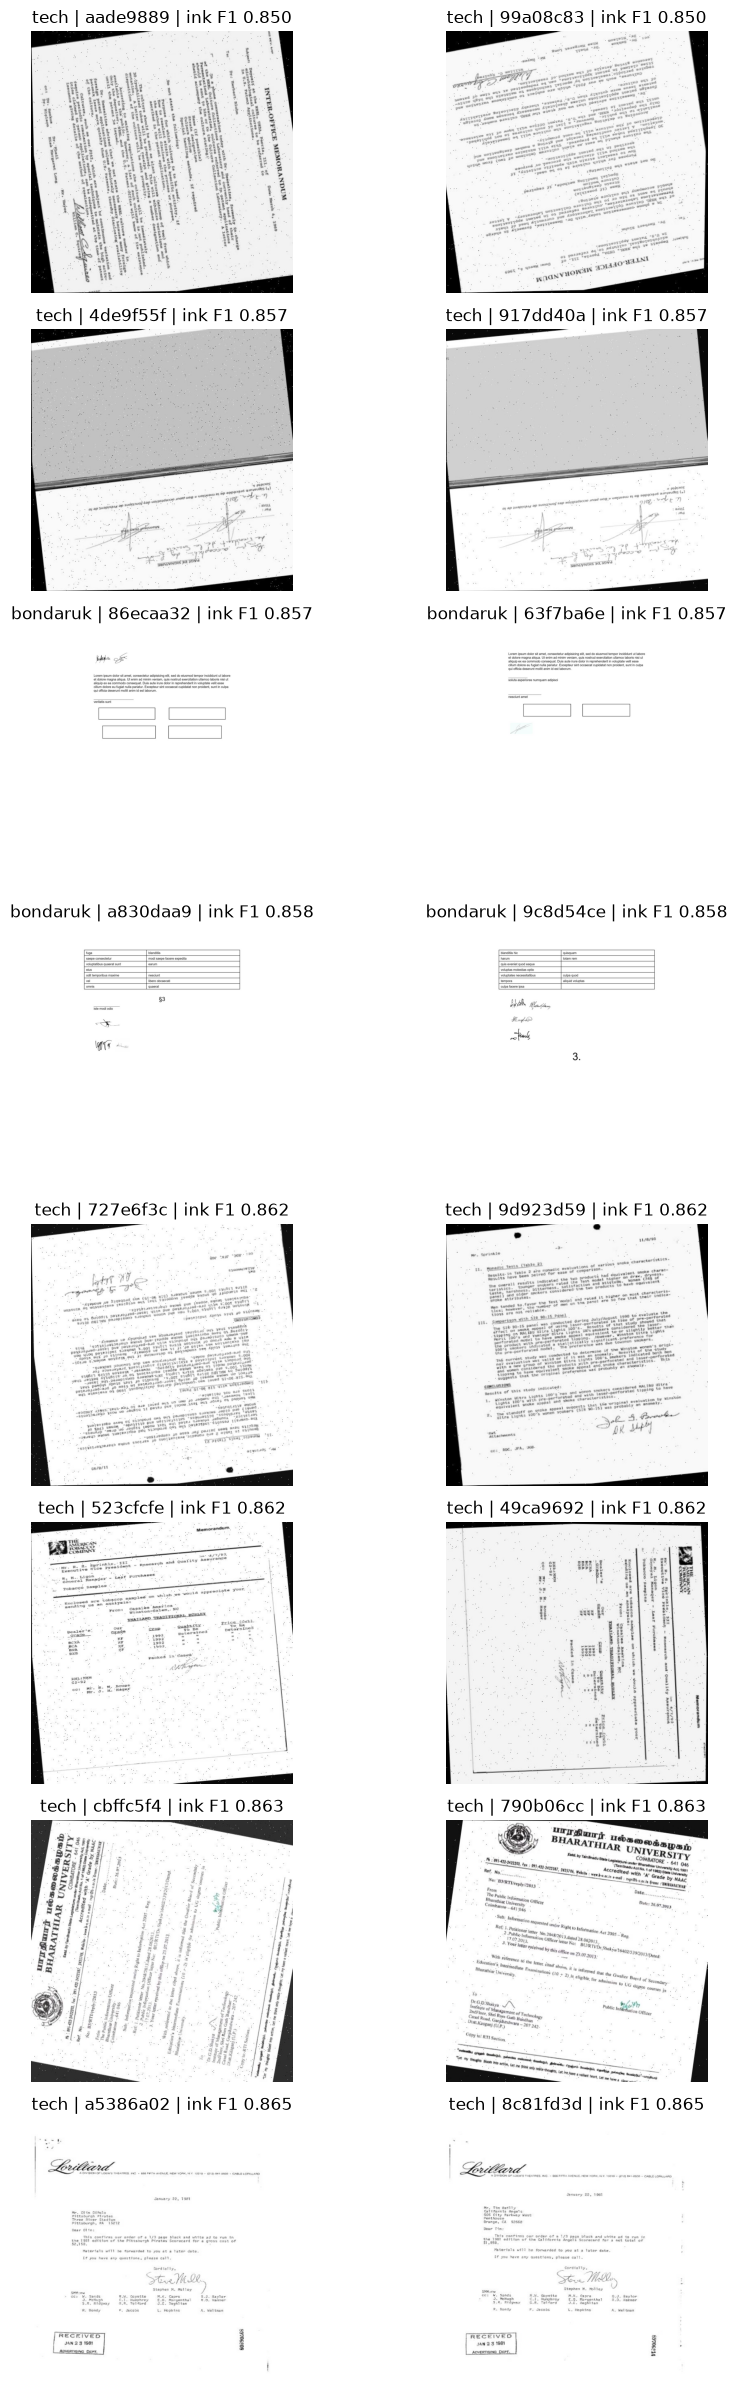

In [10]:
# Review accepted pHash pairs with the weakest content agreement first.
pairs = [edge for edge in edges if edge['reason'] == 'rotation_aware_phash']
pairs = sorted(pairs, key=lambda edge: (edge['ink_f1'], -edge['distance'], edge['a'], edge['b']))[:8]
if pairs:
    fig, axes = plt.subplots(len(pairs), 2, figsize=(10, 3 * len(pairs)), squeeze=False)
    for row, edge in enumerate(pairs):
        for column, key in enumerate(('a', 'b')):
            record = unique_records[edge[key]]
            with Image.open(record['clean_path']) as image:
                axes[row, column].imshow(image)
            axes[row, column].set_title(f"{record['source']} | {record['uid'][:8]} | ink F1 {edge['ink_f1']:.3f}")
            axes[row, column].axis('off')
    fig.tight_layout(); fig.savefig(REPORTS / 'near_duplicate_review.png', dpi=120); plt.show()


In [11]:
assert globals().get('GROUPING_READY', False), 'Rerun the revised Stage 5 grouping cell successfully before splitting.'

def assign_group_splits(records, components, ratios, seed):
    names, sources = list(ratios), sorted(source_roots)
    # Feature 0 is total images; other features count source membership (including exact-duplicate provenance).
    features = np.array([[1] + [int(any(m['source'] == s for m in r['members'])) for s in sources]
                         for r in records], dtype=float)
    targets = np.array([ratios[s] for s in names])[:, None] * features.sum(0)[None, :]
    counts = np.zeros_like(targets)
    components = [sorted(v) for v in components.values()]
    rng = random.Random(seed); rng.shuffle(components)
    components.sort(key=len, reverse=True)  # Seeded tie order, largest families assigned first.
    for indices in components:
        weight = features[indices].sum(0)
        costs = []
        for candidate in range(len(names)):
            proposal = counts.copy(); proposal[candidate] += weight
            costs.append(float((((proposal - targets) ** 2) / np.maximum(targets, 1)).sum()))
        selected = min(range(len(names)), key=lambda j: (costs[j], j))
        counts[selected] += weight
        for index in indices:
            records[index]['split'] = names[selected]
    if any(not any(r['split'] == split for r in records) for split in names):
        raise RuntimeError('A split is empty; review family sizes and ratios rather than breaking groups.')
    return records

unique_records = assign_group_splits(unique_records, groups, SPLIT_RATIOS, SEED)
split_rows = [dict(uid=r['uid'], group=r['group'], split=r['split'],
              width=r['width'], height=r['height'], boxes=len(r['boxes']),
              sources='|'.join(sorted({m['source'] for m in r['members']})),
              pixel_sha256=r['pixel_sha256']) for r in unique_records]
split_table = pd.DataFrame(split_rows)
assert split_table.groupby('group')['split'].nunique().max() == 1
assert all(unique_records[e['a']]['split'] == unique_records[e['b']]['split'] for e in edges)
split_table.to_csv(REPORTS / 'split_manifest.csv', index=False)
write_json(REPORTS / 'merged_manifest.json', unique_records)

SPLIT_DIR = {'train': 'train2017', 'val': 'val2017', 'test': 'test2017'}
(MERGED / 'annotations').mkdir(exist_ok=True)
annotation_documents = {}
for split, folder in SPLIT_DIR.items():
    image_dir = MERGED / folder; image_dir.mkdir(exist_ok=True)
    label_dir = MERGED / 'yolo_labels' / folder; label_dir.mkdir(parents=True, exist_ok=True)
    images, annotations = [], []
    for record in sorted((r for r in unique_records if r['split'] == split), key=lambda r: r['uid']):
        image_id = len(images) + 1
        filename = f"{record['uid']}.png"
        shutil.copy2(record['clean_path'], image_dir / filename)
        shutil.copy2(CLEAN / 'labels' / f"{record['uid']}.txt", label_dir / f"{record['uid']}.txt")
        images.append(dict(id=image_id, file_name=filename, width=record['width'], height=record['height']))
        for x1, y1, x2, y2 in record['boxes']:
            annotations.append(dict(id=len(annotations)+1, image_id=image_id, category_id=1,
                bbox=[x1, y1, x2-x1, y2-y1], area=(x2-x1)*(y2-y1), iscrowd=0, segmentation=[]))
    document = dict(info=dict(description='Unified signature detection; see reports for provenance'),
                    licenses=[], images=images, annotations=annotations,
                    categories=[dict(id=1, name='signature', supercategory='none')])
    write_json(MERGED / 'annotations' / f'instances_{folder}.json', document)
    annotation_documents[split] = document
write_json(CLEAN / 'class_names.json', dict(names=['signature'], class_index=0,
           label_format='class cx cy width height; coordinates normalized to each image'))
display(split_table.groupby('split').agg(images=('uid', 'size'), boxes=('boxes', 'sum'), groups=('group', 'nunique')))
print('COCO training root:', MERGED)


,images,boxes,groups
split,,,
test,397,784,178
train,3176,6188,1396
val,397,887,177


COCO training root: D:\Navtcc\Internship\Signature Identifier\signature_yolox\merged_coco


## Stage 6 — Validate the merged dataset and visualize labels

The validator checks COCO IDs and references, every decoded output image, lossless pixel identity, finite in-bounds boxes, YOLO TXT correspondence and normalization, and round-trip agreement between both annotation formats. It checks detected family/pHash separation across splits and requires positives in each split. Unlisted stale files from an earlier run are reported and ignored by the COCO manifest; use a fresh `PROJECT_ROOT` when changing datasets to keep disk contents easy to audit.

Final layout:
```text
merged_coco/
  annotations/instances_train2017.json
  annotations/instances_val2017.json
  annotations/instances_test2017.json
  train2017/<uid>.png
  val2017/<uid>.png
  test2017/<uid>.png
  yolo_labels/{train2017,val2017,test2017}/<uid>.txt
reports/{audit.csv,schemas.json,raw_inventory.csv,split_manifest.csv,...}
```

Inspect annotated samples from **each source** and each final split. Source plots include shared provenance after exact deduplication; they are membership counts and need not sum to the number of unique merged images. No readiness claim is made until the runtime checks pass.


In [ ]:
def validate_merged():
    errors, stale, seen_pixels, seen_groups = [], [], {}, {}
    manifest = {r['uid']: r for r in unique_records}
    for split, folder in SPLIT_DIR.items():
        doc = json.loads((MERGED / 'annotations' / f'instances_{folder}.json').read_text())
        assert doc['categories'] == [dict(id=1, name='signature', supercategory='none')]
        ids = [im['id'] for im in doc['images']]; aids = [a['id'] for a in doc['annotations']]
        assert len(ids) == len(set(ids)) and len(aids) == len(set(aids))
        assert all(a['image_id'] in set(ids) and a['category_id'] == 1 for a in doc['annotations'])
        assert doc['images'] and doc['annotations'], f'{split} needs both images and positive boxes.'
        by_image = defaultdict(list)
        for annotation in doc['annotations']:
            by_image[annotation['image_id']].append(annotation)
        expected_images, expected_labels = set(), set()
        for im in tqdm(doc['images'], desc=f'Validate {split}'):
            uid = Path(im['file_name']).stem; record = manifest[uid]
            image_path = MERGED / folder / im['file_name']
            label_path = MERGED / 'yolo_labels' / folder / f'{uid}.txt'
            expected_images.add(image_path.name); expected_labels.add(label_path.name)
            assert image_path.is_file() and label_path.is_file()
            with Image.open(image_path) as image:
                image.load(); w, h = image.size
                digest = hashlib.sha256(f'{w}x{h}:RGB:'.encode() + image.convert('RGB').tobytes()).hexdigest()
            assert digest == record['pixel_sha256'] and (w, h) == (im['width'], im['height'])
            decoded = cv2.imread(str(image_path)); assert decoded is not None and decoded.shape[:2] == (h, w)
            assert digest not in seen_pixels, 'Exact duplicates survived deduplication.'
            seen_pixels[digest] = split
            assert seen_groups.get(record['group'], split) == split
            seen_groups[record['group']] = split
            label_lines = [line.split() for line in label_path.read_text().splitlines() if line.strip()]
            annotations = by_image[im['id']]
            assert len(label_lines) == len(annotations) == len(record['boxes'])
            for fields, annotation in zip(label_lines, annotations):
                assert len(fields) == 5 and fields[0] == '0'
                cx, cy, bw, bh = map(float, fields[1:])
                values = np.array([cx, cy, bw, bh]); assert np.isfinite(values).all()
                assert 0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1
                assert cx-bw/2 >= -1e-9 and cy-bh/2 >= -1e-9 and cx+bw/2 <= 1+1e-9 and cy+bh/2 <= 1+1e-9
                x, y, width, height = annotation['bbox']
                assert np.isfinite(annotation['bbox']).all() and width > 0 and height > 0
                assert x >= 0 and y >= 0 and x+width <= w+1e-7 and y+height <= h+1e-7
                assert math.isclose(annotation['area'], width*height, rel_tol=1e-9)
                reconstructed = [(cx-bw/2)*w, (cy-bh/2)*h, bw*w, bh*h]
                assert np.allclose(reconstructed, annotation['bbox'], atol=1e-4, rtol=0)
        stale.extend(str(p) for p in (MERGED / folder).iterdir() if p.is_file() and p.name not in expected_images)
        stale.extend(str(p) for p in (MERGED / 'yolo_labels' / folder).iterdir() if p.is_file() and p.name not in expected_labels)
        with contextlib.redirect_stdout(io.StringIO()):
            api = COCO(str(MERGED / 'annotations' / f'instances_{folder}.json'))
        assert len(api.getImgIds()) == len(doc['images']) and api.getCatIds() == [1]
    assert all(unique_records[e['a']]['split'] == unique_records[e['b']]['split'] for e in edges)
    write_json(REPORTS / 'stale_unlisted_files.json', stale)
    return dict(ready=True, unique_images=len(unique_records), boxes=sum(len(r['boxes']) for r in unique_records),
                groups=len(groups), detected_relationships=len(edges), stale_unlisted_files=len(stale),
                seed=SEED, ratios=SPLIT_RATIOS, quarantine_events=sum(r['action']=='quarantine' for r in audit),
                annotations={s: sha256_file(MERGED / 'annotations' / f'instances_{d}.json') for s, d in SPLIT_DIR.items()},
                prepared_manifest_sha256=sha256_file(REPORTS / 'merged_manifest.json'))

DATA_VALIDATION = validate_merged()
write_json(REPORTS / 'validation.json', DATA_VALIDATION)
print(json.dumps(DATA_VALIDATION, indent=2))
if DATA_VALIDATION['quarantine_events']:
    print('Review audit.csv and quarantined_records.json before setting ACCEPT_QUARANTINE=True for training.')


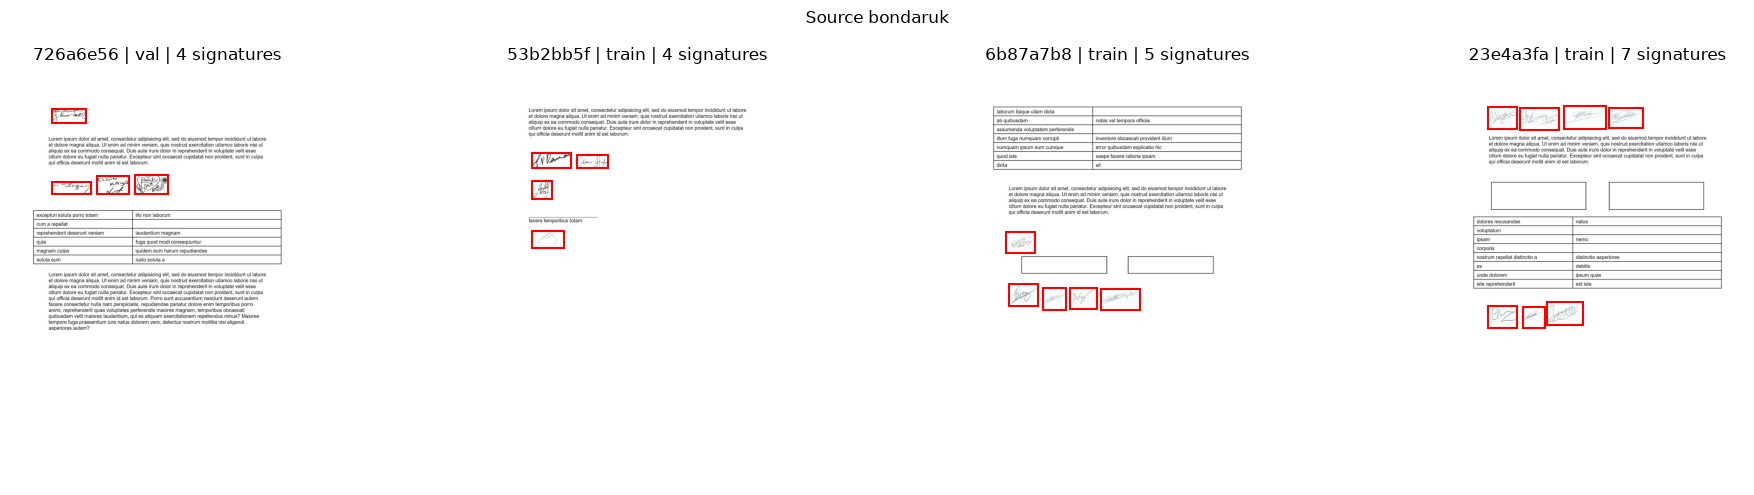

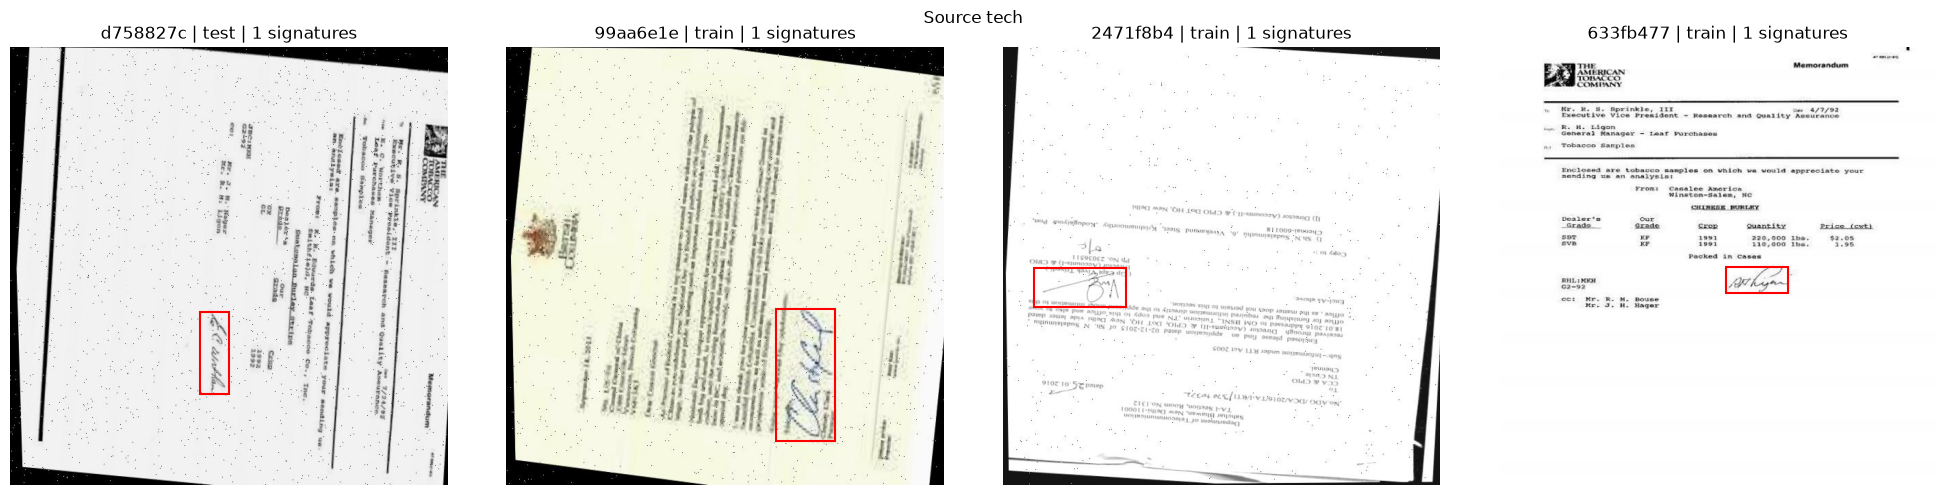

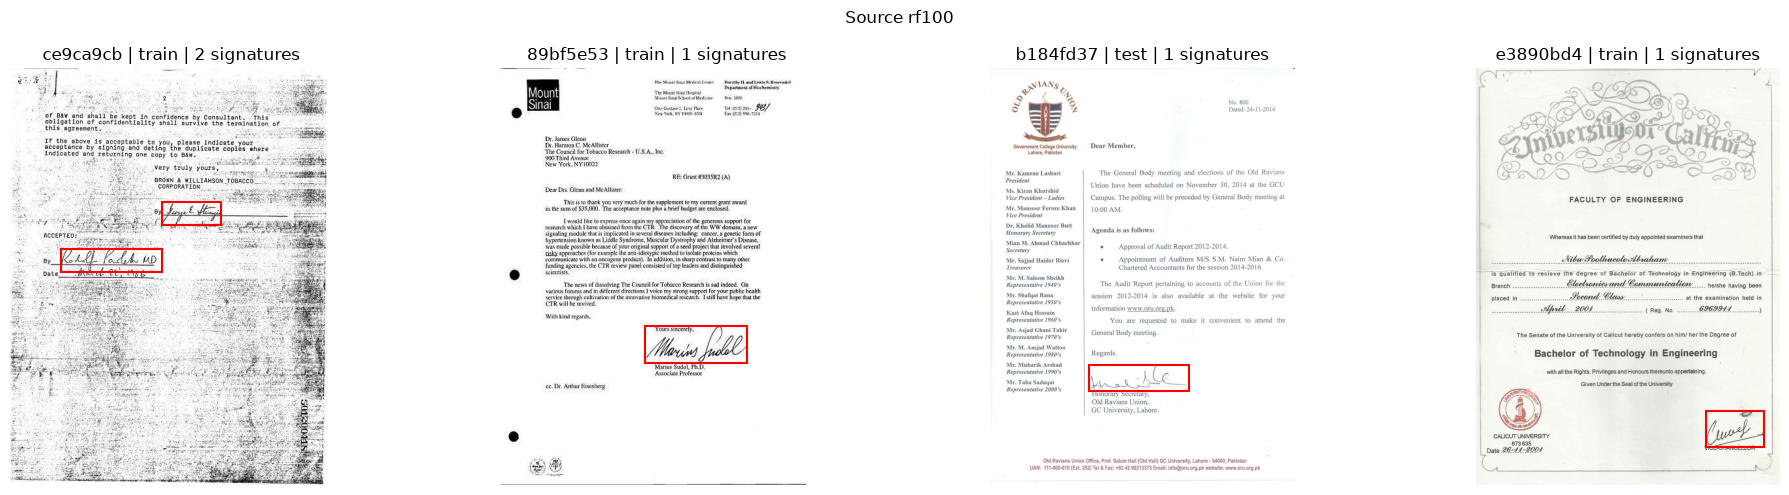

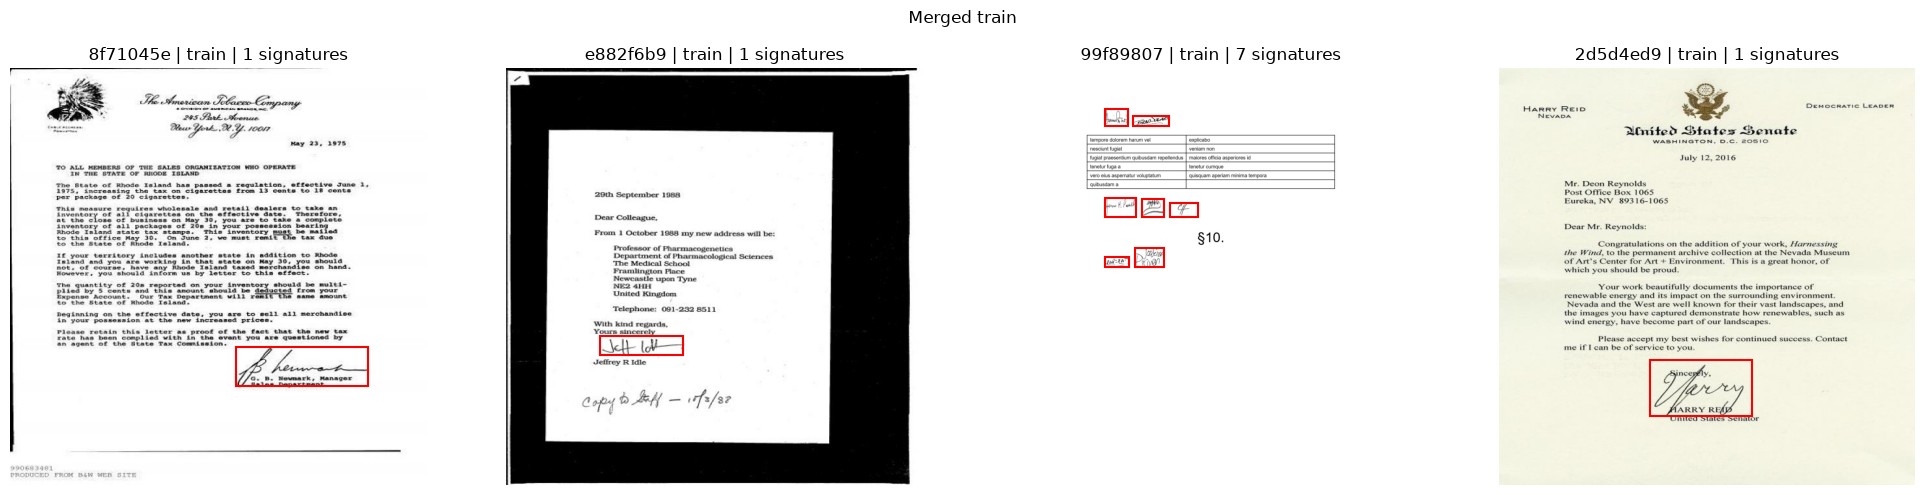

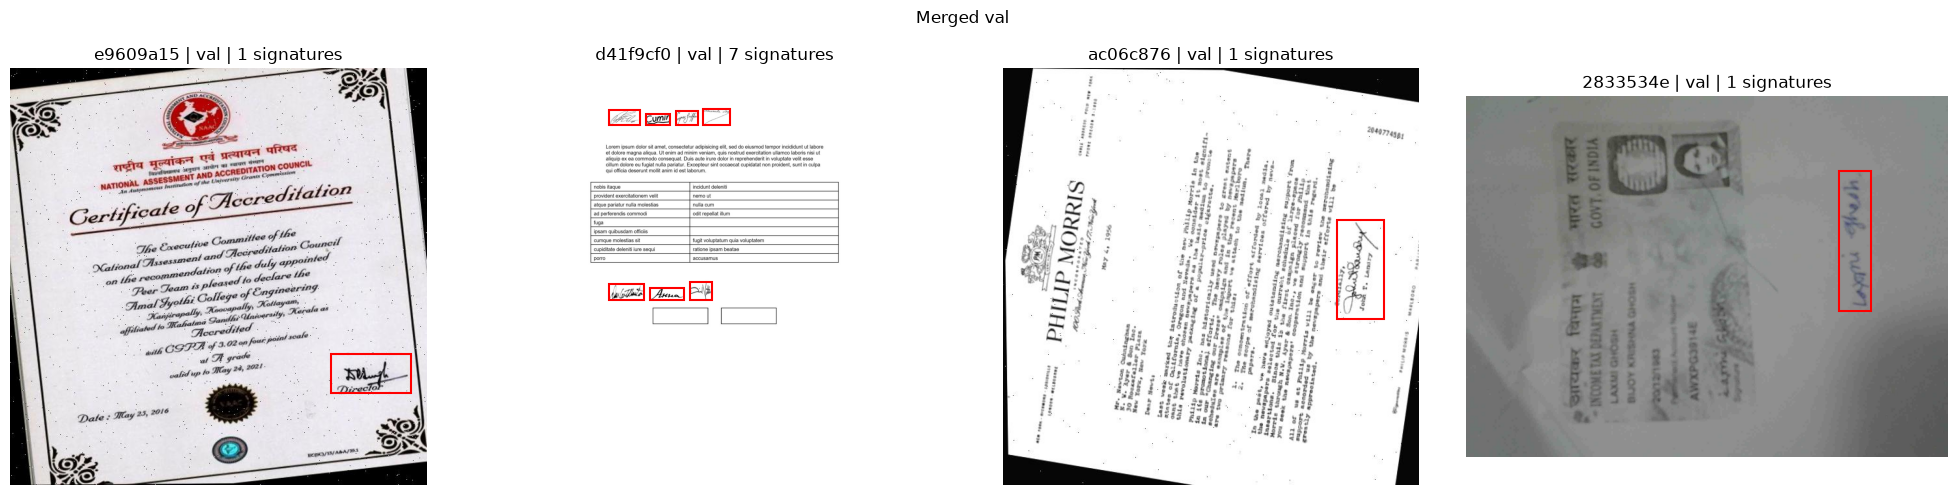

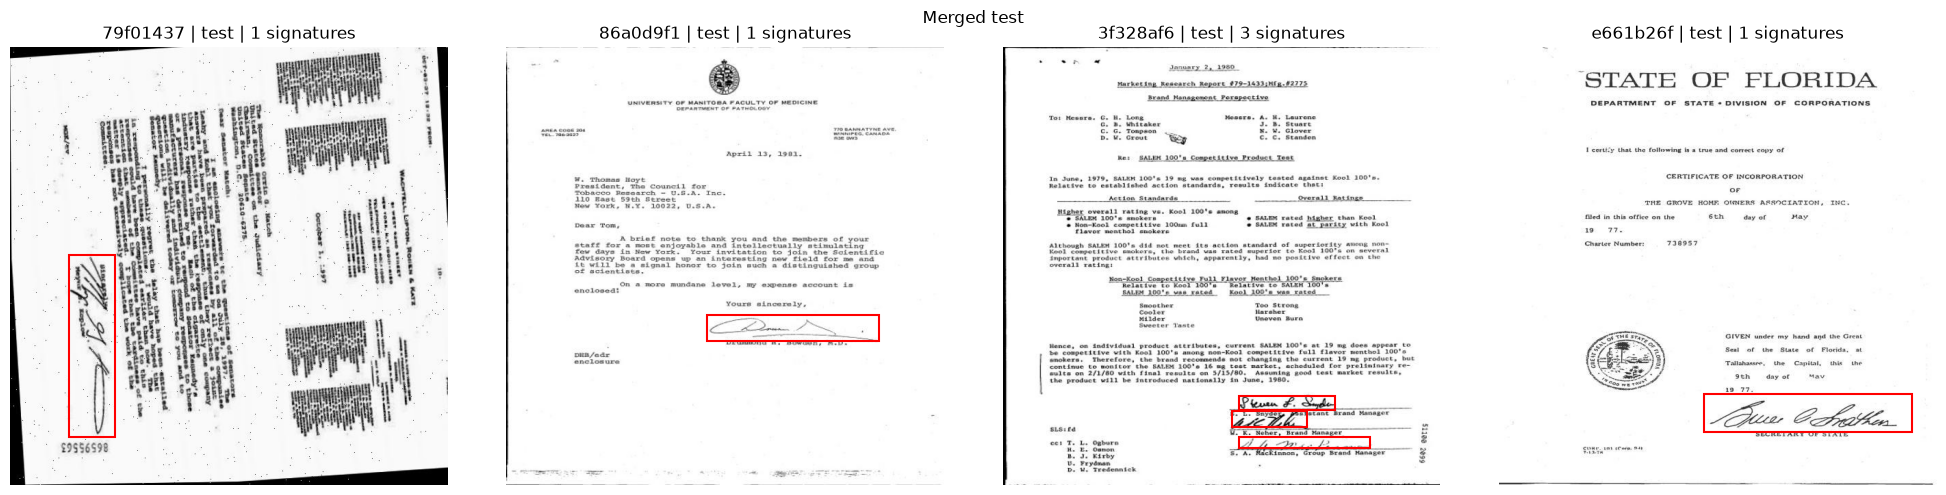

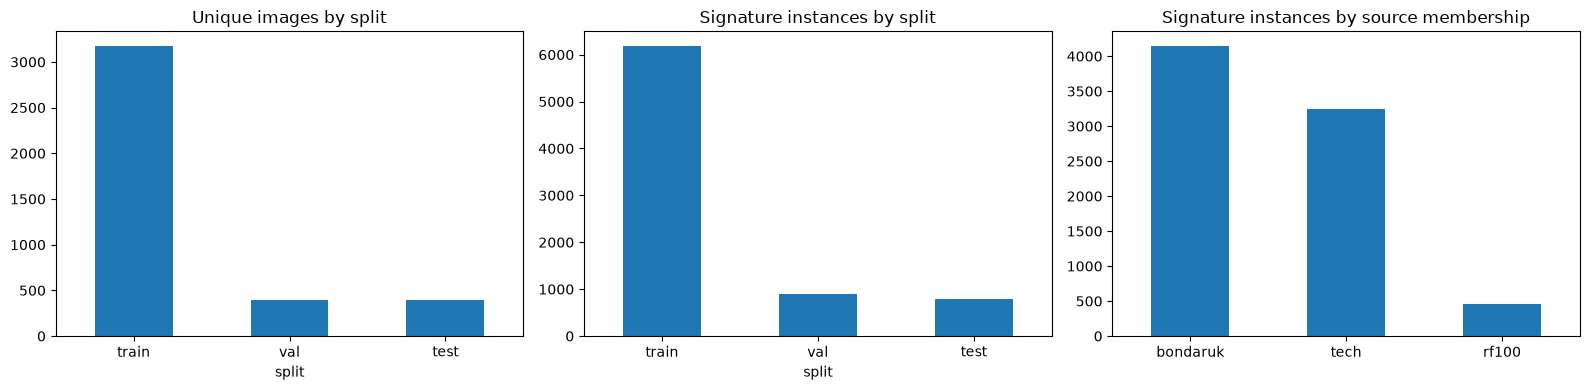

,action,reason,events
0,inspect,category_mapping,8
1,repair,clip_minor_boundary_overshoot,4
2,repair,recompute_bbox_area,1831


In [13]:
def show_annotations(records, title, count=4):
    selected = random.Random(SEED).sample(records, min(count, len(records)))
    if not selected:
        return
    fig, axes = plt.subplots(1, len(selected), figsize=(5*len(selected), 5), squeeze=False)
    for ax, record in zip(axes[0], selected):
        with Image.open(record['clean_path']) as image:
            ax.imshow(image)
        for x1, y1, x2, y2 in record['boxes']:
            ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='red', linewidth=1.5))
        ax.set_title(f"{record['uid'][:8]} | {record['split']} | {len(record['boxes'])} signatures")
        ax.axis('off')
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(REPORTS / (re.sub(r'[^a-z0-9]+', '_', title.casefold()) + '.png'), dpi=140); plt.show()

for source in source_roots:
    show_annotations([r for r in unique_records if any(m['source'] == source for m in r['members'])], f'Source {source}')
for split in SPLIT_DIR:
    show_annotations([r for r in unique_records if r['split'] == split], f'Merged {split}')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
split_table.groupby('split').size().reindex(SPLIT_DIR).plot.bar(ax=axes[0], title='Unique images by split', rot=0)
split_table.groupby('split')['boxes'].sum().reindex(SPLIT_DIR).plot.bar(ax=axes[1], title='Signature instances by split', rot=0)
source_box_counts = {s: sum(len(r['boxes']) for r in unique_records if any(m['source']==s for m in r['members'])) for s in source_roots}
pd.Series(source_box_counts).plot.bar(ax=axes[2], title='Signature instances by source membership', rot=0)
fig.tight_layout(); fig.savefig(REPORTS / 'merged_distributions.png', dpi=150); plt.show()
display(pd.DataFrame(audit).groupby(['action', 'reason']).size().rename('events').reset_index())


## Stage 7 — Configure official YOLOX-Tiny and transfer learning

The generated experiment **inherits the official Tiny experiment from the source archive**. It changes class count, data paths, training settings, and label capacity. The official SGD/Nesterov optimizer, cosine schedule, training/evaluation dataloaders, and augmentation classes are inherited. This local-GPU configuration targets **30 total epochs**, with three warmup epochs and a final five-epoch augmentation-free phase. `learning_rate=0.00125` retains the previous run's peak total rate; the batch benchmark does not automatically double it. The new cosine schedule is recomputed for the shorter horizon, so this is a modified continuation rather than reproduction of the old 100-epoch schedule. Horizontal flips and mixup remain off.

**Resume without repeating preprocessing:** in your current kernel, rerun the configuration cell, then all Stage 7 code cells, Stage 8, and Stage 9. Stage 7 reloads the saved merged manifests; it does not inspect, group, or export images again. After a kernel restart, run configuration, the Stage 1 dependencies and official-source cells, then jump here. The existing `reports/merged_manifest.json`, validation report, annotations, and checkpoint are required. For a fresh training run without a checkpoint, set `TRAIN['resume']=False` and choose a new experiment name.

`multiscale_range=0` uses a fixed input size. The Tiny experiment's inherited `random_size` is removed so this setting actually takes effect. Label capacity is automatically raised to cover the worst-case four-image mosaic (or eight-image mixup), preventing truncation at the official default cap. Very small objects can still be filtered by the official training transform when projected sides are at most one pixel; a report below quantifies this risk without deleting source labels.

Download the official COCO-trained **YOLOX-Tiny** weights. The one-class prediction layers have different shapes and are freshly initialized; every other target tensor must be present and shape-compatible. A transfer report lists exactly which tensors were excluded. The resulting full one-class initialization is passed to the official trainer.


In [24]:
# Restore prepared artifacts; no image decoding, grouping, or dataset rewriting is needed.
prepared_manifest = REPORTS / 'merged_manifest.json'
if not prepared_manifest.is_file():
    raise FileNotFoundError('Complete Stages 2–6 once before using the optimized resume path.')
unique_records = json.loads(prepared_manifest.read_text(encoding='utf-8'))
SPLIT_DIR = {'train': 'train2017', 'val': 'val2017', 'test': 'test2017'}
annotation_documents = {s: json.loads((MERGED / 'annotations' / f'instances_{d}.json').read_text(encoding='utf-8'))
                        for s, d in SPLIT_DIR.items()}
CONFIG_DIR = PROJECT_ROOT / 'experiments'; CONFIG_DIR.mkdir(exist_ok=True)
EXP_FILE = CONFIG_DIR / 'signature_yolox_tiny.py'
TRAIN_CONFIG_FILE = CONFIG_DIR / 'signature_train_config.json'
max_objects = max(len(r['boxes']) for r in unique_records)
mosaic_factor = (8 if TRAIN['enable_mixup'] else 4) if TRAIN['mosaic_prob'] > 0 else 1
train_settings = dict(TRAIN)
train_settings['max_labels'] = max(TRAIN['max_labels'], mosaic_factor * max_objects, 1)
print('Padded label capacity:', train_settings['max_labels'], '| maximum original boxes per image:', max_objects)
train_config = dict(train=train_settings, seed=SEED, data_dir=str(MERGED),
                    output_dir=str(OUTPUTS), yolox_root=str(YOLOX_ROOT))
write_json(TRAIN_CONFIG_FILE, train_config)
experiment_code = '''import json
import importlib.util
from pathlib import Path
import torch
from yolox.core import Trainer

_cfg = json.loads(Path(__file__).with_name('signature_train_config.json').read_text())
_spec = importlib.util.spec_from_file_location('official_tiny_for_signatures',
    Path(_cfg['yolox_root']) / 'exps' / 'default' / 'yolox_tiny.py')
_tiny = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_tiny)

class SignatureTrainer(Trainer):
    # Keep the official loop, optimizer, EMA, losses and checkpoint implementation.
    def before_train(self):
        if _cfg['train']['fast_cudnn']:
            torch.backends.cudnn.deterministic = False
            torch.backends.cudnn.benchmark = True
        super().before_train()
        # Resume may change batch size and schedule length. Set the revised LR BEFORE its first update.
        resumed_lr = self.lr_scheduler.update_lr(self.start_epoch * self.max_iter)
        for group in self.optimizer.param_groups:
            group['lr'] = resumed_lr

class Exp(_tiny.Exp):
    def __init__(self):
        super().__init__()
        c = _cfg['train']
        self.num_classes = 1
        self.seed = _cfg['seed']
        self.data_dir = _cfg['data_dir']
        self.output_dir = _cfg['output_dir']
        self.exp_name = c['experiment']
        self.input_size = (c['input_size'], c['input_size'])
        self.test_size = self.input_size
        if hasattr(self, 'random_size'):
            del self.random_size
        self.multiscale_range = c['multiscale_range']
        self.train_ann = 'instances_train2017.json'
        self.val_ann = 'instances_val2017.json'
        self.test_ann = 'instances_test2017.json'
        self.max_epoch = c['epochs']
        self.basic_lr_per_img = c['learning_rate'] / c['batch_size']
        self.data_num_workers = c['workers']
        self.test_conf = c['test_conf']
        self.nmsthre = c['nms']
        self.max_labels = c['max_labels']
        for key in ('momentum', 'weight_decay', 'warmup_epochs', 'no_aug_epochs',
                    'eval_interval', 'mosaic_prob', 'enable_mixup', 'flip_prob',
                    'hsv_prob', 'degrees', 'shear', 'translate', 'save_history_ckpt'):
            setattr(self, key, c[key])
        self.mosaic_scale = tuple(c['mosaic_scale'])
        self.print_interval = 20

    def get_data_loader(self, batch_size, is_distributed, no_aug=False, cache_img=False):
        loader = super().get_data_loader(batch_size, is_distributed, no_aug, cache_img)
        loader.dataset.preproc.max_labels = self.max_labels
        loader.dataset._dataset.preproc.max_labels = self.max_labels
        return loader

    def get_trainer(self, args):
        trainer = SignatureTrainer(self, args)
        if not args.resume:
            # Save the first validated model even when its AP is zero.
            trainer.best_ap = -1.0
        return trainer
'''
EXP_FILE.write_text(experiment_code, encoding='utf-8')
# Syntax-only checking here does not train a model. It runs only when you execute this cell.
compile(experiment_code, str(EXP_FILE), 'exec')
from yolox.exp import get_exp
# get_exp uses Python's import cache; invalidate it after rewriting the configuration.
sys.modules.pop(EXP_FILE.stem, None)
exp = get_exp(str(EXP_FILE), None)
assert exp.depth == 0.33 and exp.width == 0.375 and exp.num_classes == 1
small_object_rows = []
for r in unique_records:
    scale = min(exp.input_size[0]/r['height'], exp.input_size[1]/r['width'])
    tiny = sum(min(x2-x1, y2-y1)*scale <= 1 for x1, y1, x2, y2 in r['boxes'])
    if tiny:
        small_object_rows.append(dict(uid=r['uid'], split=r['split'], boxes_at_most_one_pixel=tiny))
pd.DataFrame(small_object_rows, columns=['uid', 'split', 'boxes_at_most_one_pixel']).to_csv(REPORTS / 'small_object_risk.csv', index=False)
print('Boxes with a projected side <= 1 pixel at base input size:', sum(r['boxes_at_most_one_pixel'] for r in small_object_rows))
print('Experiment:', EXP_FILE)


Padded label capacity: 300 | maximum original boxes per image: 17
Boxes with a projected side <= 1 pixel at base input size: 0
Experiment: D:\Navtcc\Internship\Signature Identifier\signature_yolox\experiments\signature_yolox_tiny.py


In [25]:
PRETRAINED = WEIGHTS / 'yolox_tiny_coco.pth'
FINETUNE_INIT = WEIGHTS / 'signature_yolox_tiny_initialization.pth'
weights_url = 'https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_tiny.pth'
weights_digest = download_file(weights_url, PRETRAINED, WEIGHTS_SHA256)
# Trusted official checkpoint only. Do not replace this with an untrusted pickle.
checkpoint = torch.load(PRETRAINED, map_location='cpu', weights_only=False)
assert isinstance(checkpoint, dict) and isinstance(checkpoint.get('model'), dict)
model = exp.get_model()
target_state, source_state = model.state_dict(), checkpoint['model']
compatible = {k: value for k, value in source_state.items() if k in target_state and value.shape == target_state[k].shape}
missing = sorted(set(target_state) - set(compatible))
expected_head_keys = {f'head.cls_preds.{level}.{parameter}' for level in range(3) for parameter in ('weight', 'bias')}
assert set(missing) == expected_head_keys, f'Unexpected transfer mismatch; this may not be Tiny: {missing}'
loaded = model.load_state_dict(compatible, strict=False)
assert set(loaded.missing_keys) == expected_head_keys and not loaded.unexpected_keys
torch.save({'model': model.state_dict()}, FINETUNE_INIT)
write_json(REPORTS / 'transfer_learning.json', dict(weights_url=weights_url, sha256=weights_digest,
           tensors_loaded=len(compatible), reinitialized=missing,
           depth=exp.depth, width=exp.width, classes=exp.num_classes,
           initialization_sha256=sha256_file(FINETUNE_INIT)))
print('Loaded', len(compatible), 'pretrained tensors; initialized', len(missing), 'one-class prediction tensors.')
del checkpoint, source_state, target_state, compatible, model
# Remove the preview model so a later get_model() creates a fresh instance.
if hasattr(exp, 'model'):
    del exp.model


Loaded 456 pretrained tensors; initialized 6 one-class prediction tensors.


### Local GPU batch benchmark and dataloader preflight

When you run this cell with `AUTO_SELECT_BATCH_SIZE=True`, it compares batch 8 and 16 using two warmup and six timed forward/backward passes on a temporary copy of your resumed model. There are **no optimizer steps or checkpoint writes**. It uses one real training minibatch, so this is a short compute-throughput comparison, not a full-epoch benchmark. Out-of-memory trials are rejected; a candidate must leave approximately 20% device-memory headroom. Batch 16 is selected only if it is at least 5% faster in images/second; otherwise batch 8 remains selected. Results are saved to `reports/batch_benchmark.json`.

The cell writes the selected batch to the training configuration and then reads official training/validation batches to verify shapes and class indices. The benchmark and dataloader checks execute only when you run this cell. Set `AUTO_SELECT_BATCH_SIZE=False` to retain the manually configured batch. Fast cuDNN is enabled by default for this fixed input size; it trades strict deterministic kernels for potential speed. The full official training loop remains in Stage 8.


In [26]:
import time, gc
DATALOADERS_READY = False

def checkpoint_for_training():
    if TRAIN['resume']:
        return Path(TRAIN['resume_checkpoint']).expanduser().resolve() if TRAIN['resume_checkpoint'] else OUTPUTS / TRAIN['experiment'] / 'latest_ckpt.pth'
    return WEIGHTS / 'signature_yolox_tiny_initialization.pth'

def benchmark_batch(batch_size, cpu_images, cpu_targets, model_state):
    trial_exp = trial_model = inputs = targets = None
    result = dict(batch_size=batch_size, status='out_of_memory', images_per_second=None, peak_reserved_mb=None)
    try:
        gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        trial_exp = get_exp(str(EXP_FILE), None)
        trial_model = trial_exp.get_model()
        trial_model.load_state_dict(model_state, strict=True)
        trial_model.cuda().train()
        dtype = torch.float16 if TRAIN['fp16'] else torch.float32
        inputs = cpu_images[:batch_size].to(device='cuda', dtype=dtype)
        targets = cpu_targets[:batch_size].to(device='cuda', dtype=dtype)
        def step():
            trial_model.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=TRAIN['fp16']):
                output = trial_model(inputs, targets)
            loss = output['total_loss']
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite loss during batch benchmark; inspect the resumed checkpoint.')
            loss.backward()
        for _ in range(2):
            step()
        torch.cuda.synchronize(); started = time.perf_counter()
        for _ in range(6):
            step()
        torch.cuda.synchronize(); seconds = time.perf_counter() - started
        peak = torch.cuda.max_memory_reserved()
        free, total = torch.cuda.mem_get_info()
        other_usage = max(0, total - free - torch.cuda.memory_reserved())
        enough_headroom = peak + other_usage < total * 0.80
        result.update(status='ok' if enough_headroom else 'insufficient_headroom',
                      images_per_second=6*batch_size/seconds, peak_reserved_mb=peak/(1024**2))
    except torch.cuda.OutOfMemoryError:
        pass  # This candidate is reported as rejected; the smaller candidate can still be selected.
    finally:
        trial_exp = trial_model = inputs = targets = None
        gc.collect(); torch.cuda.empty_cache()
    return result

if TRAIN['resume'] or AUTO_SELECT_BATCH_SIZE:
    resume_file = checkpoint_for_training()
    if not resume_file.is_file():
        raise FileNotFoundError(f'Configured training checkpoint is missing: {resume_file}')
    resume_state = torch.load(resume_file, map_location='cpu', weights_only=False)
    completed_epochs = int(resume_state.get('start_epoch', 0)) if TRAIN['resume'] else 0
    print(f'Completed checkpoint epochs: {completed_epochs}; total target: {TRAIN["epochs"]}; remaining: {max(0, TRAIN["epochs"]-completed_epochs)}')
    if TRAIN['resume'] and completed_epochs >= TRAIN['epochs']:
        raise RuntimeError('This checkpoint already reached the target. Increase the total epoch target or skip Stage 8 and evaluate.')
    if AUTO_SELECT_BATCH_SIZE:
        assert torch.cuda.is_available(), 'The batch benchmark requires your CUDA GPU.'
        if TRAIN['fast_cudnn']:
            torch.backends.cudnn.deterministic = False; torch.backends.cudnn.benchmark = True
        sample_exp = get_exp(str(EXP_FILE), None)
        sample_exp.data_num_workers = 0  # One sample batch; avoid spawning workers twice on Windows.
        sample_loader = sample_exp.get_data_loader(16, is_distributed=False, no_aug=False, cache_img=False)
        sample_iterator = iter(sample_loader)
        sample_images, sample_targets, _, _ = next(sample_iterator)
        del sample_iterator, sample_loader, sample_exp
        results = [benchmark_batch(bs, sample_images, sample_targets, resume_state['model']) for bs in (8, 16)]
        del sample_images, sample_targets
        usable = [row for row in results if row['status'] == 'ok']
        if not usable:
            write_json(REPORTS / 'batch_benchmark.json', dict(results=results, selected=None))
            raise RuntimeError('Neither batch passed memory checks. Close other GPU workloads or choose a smaller manual batch and disable auto selection.')
        selected = min(usable, key=lambda row: row['batch_size'])
        faster = max(usable, key=lambda row: row['images_per_second'])
        if faster['images_per_second'] >= selected['images_per_second'] * 1.05:
            selected = faster
        TRAIN['batch_size'] = selected['batch_size']
        train_settings['batch_size'] = TRAIN['batch_size']
        train_config['train'] = train_settings
        write_json(TRAIN_CONFIG_FILE, train_config)
        write_json(REPORTS / 'batch_benchmark.json', dict(results=results, selected=TRAIN['batch_size'],
                   note='Temporary-model forward/backward only; no optimizer steps; total learning rate unchanged.'))
        display(pd.DataFrame(results)); print('Selected training batch:', TRAIN['batch_size'])
        sys.modules.pop(EXP_FILE.stem, None)
        exp = get_exp(str(EXP_FILE), None)
    del resume_state

train_loader = exp.get_data_loader(TRAIN['batch_size'], is_distributed=False, no_aug=False, cache_img=False)
train_iterator = iter(train_loader)
train_images, train_targets, _, _ = next(train_iterator)
val_loader = exp.get_eval_loader(TRAIN['batch_size'], is_distributed=False)
val_images, _, _, _ = next(iter(val_loader))
assert tuple(train_images.shape[1:]) == (3, TRAIN['input_size'], TRAIN['input_size'])
assert tuple(val_images.shape[1:]) == tuple(train_images.shape[1:])
assert train_targets.shape[1:] == (train_settings['max_labels'], 5)
assert torch.isfinite(train_images).all() and torch.isfinite(train_targets).all()
assert (train_targets[..., 0] == 0).all(), 'Only class index 0 is permitted.'
assert len(train_loader.dataset) == len(annotation_documents['train']['images'])
assert val_loader.dataset.class_ids == [1] and val_loader.dataset._classes == ('signature',)
print('Train batch:', tuple(train_images.shape), '| labels:', tuple(train_targets.shape))
print('Validation batch:', tuple(val_images.shape))
del train_iterator, train_loader, val_loader, train_images, train_targets, val_images
if hasattr(exp, 'dataset'):
    del exp.dataset
DATALOADERS_READY = True


Completed checkpoint epochs: 7; total target: 30; remaining: 23
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


D:\Navtcc\Internship\Signature Identifier\signature_yolox\YOLOX-0.3.0\yolox\models\yolo_head.py:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


,batch_size,status,images_per_second,peak_reserved_mb
0,8,ok,39.195634,592.0
1,16,ok,35.966269,1154.0


Selected training batch: 8
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Train batch: (8, 3, 416, 416) | labels: (8, 300, 5)
Validation batch: (8, 3, 416, 416)


## Stage 8 — Train with the official YOLOX pipeline

`RUN_TRAINING=True` is the default. Training uses the official `tools/train.py` entry point with one CUDA GPU, your experiment, mixed precision, and TensorBoard logging. The local-laptop configuration resumes the existing experiment toward **30 total epochs**, using **416 × 416** inputs and the batch selected in Stage 7. Official SGD updates, losses, EMA, loop and checkpoint implementation are retained. A small Trainer subclass applies the revised schedule's learning rate before the first resumed optimizer step and enables optional fast cuDNN kernels.

**Continue your stopped run:** rerun configuration, all Stage 7 code cells, this Stage 8 cell, and both Stage 9 code cells. The last log showed seven completed epochs, so that checkpoint would resume at epoch eight with 23 epochs remaining; the checkpoint header printed in Stage 7 is authoritative. The interrupted part of an epoch is repeated. Dataset preparation does not need to be repeated. For a restarted kernel, follow the setup instructions in Stage 7 first.

Validation runs every five epochs initially; the official trainer switches to every epoch in its final augmentation-free phase. New per-epoch history checkpoints are disabled. `latest_ckpt.pth`, the validation-selected `best_ckpt.pth`, official phase checkpoints, logs and TensorBoard events remain available. Earlier epoch files are retained. Training output is also saved to `reports/training_console.log`. Changing batch and schedule, plus optional non-deterministic cuDNN kernels, changes the optimization trajectory; throughput and final accuracy must be assessed on your run.

For resume, set `TRAIN['resume']=True` and optionally set `resume_checkpoint` to your own checkpoint path, then rerun the experiment-writing cell. The official trainer restores model, optimizer, and start epoch; it is not a bit-for-bit restoration of random generators/AMP scaler. For a new run, choose a new experiment name. A run with an existing latest checkpoint is protected from accidental overwrite.

Training checks that settings match Stage 7. By default it reuses the successful validation report when annotation hashes match the prior validated snapshot and verifies image/label file presence and counts. This avoids another full image decode. It assumes prepared image contents were not edited after validation; set `FORCE_FULL_VALIDATION=True` and run Stage 6 if images, labels or grouping changed. Exclusions still require `ACCEPT_QUARANTINE=True`.


In [27]:
def verify_prepared_training_data():
    if FORCE_FULL_VALIDATION:
        if 'validate_merged' not in globals():
            raise RuntimeError('Run Stage 6 in this kernel before requesting a full revalidation.')
        status = validate_merged()
        write_json(REPORTS / 'validation.json', status)
        return dict(status, validation_mode='full_image_and_label_validation')
    status = json.loads((REPORTS / 'validation.json').read_text(encoding='utf-8'))
    previous_path = REPORTS / 'training_run.json'
    previous = json.loads(previous_path.read_text(encoding='utf-8')) if previous_path.is_file() else {}
    baseline = status.get('annotations') or previous.get('annotations')
    current = {s: sha256_file(MERGED / 'annotations' / f'instances_{d}.json') for s, d in SPLIT_DIR.items()}
    if not status.get('ready') or not baseline or current != baseline:
        raise RuntimeError('Prepared annotation snapshot changed or no validated hash baseline exists. Run Stage 6 before training.')
    manifest_digest = sha256_file(REPORTS / 'merged_manifest.json')
    if status.get('prepared_manifest_sha256') and status['prepared_manifest_sha256'] != manifest_digest:
        raise RuntimeError('Prepared split manifest changed. Run Stage 6 before training.')
    images = boxes = 0
    for split, folder in SPLIT_DIR.items():
        document = json.loads((MERGED / 'annotations' / f'instances_{folder}.json').read_text(encoding='utf-8'))
        images += len(document['images']); boxes += len(document['annotations'])
        for image in document['images']:
            image_path = MERGED / folder / image['file_name']
            label_path = MERGED / 'yolo_labels' / folder / (Path(image['file_name']).stem + '.txt')
            if not image_path.is_file() or not label_path.is_file():
                raise FileNotFoundError(f'Prepared image or label missing: {image_path}')
    assert images == status['unique_images'] == len(unique_records) and boxes == status['boxes']
    print('Reusing full validation; annotation hashes, prepared file presence and counts passed.')
    return dict(status, annotations=current, prepared_manifest_sha256=manifest_digest,
                validation_mode='cached_validation_with_hash_and_presence_checks')

def train_official_yolox():
    assert torch.cuda.is_available(), 'Training requires CUDA: use the configured local NVIDIA GPU or select a Colab GPU runtime.'
    assert DATALOADERS_READY
    saved = json.loads(TRAIN_CONFIG_FILE.read_text())['train']
    assert all(saved[k] == v for k, v in TRAIN.items() if k != 'max_labels'), 'Settings changed: rerun Stage 7 and dataloader preflight.'
    status = verify_prepared_training_data()
    assert status['ready']
    if status['quarantine_events'] and not ACCEPT_QUARANTINE:
        raise RuntimeError('Review audit.csv and quarantined_records.json, then set ACCEPT_QUARANTINE=True if these exclusions are acceptable.')
    run_dir = OUTPUTS / TRAIN['experiment']
    latest = run_dir / 'latest_ckpt.pth'
    if not TRAIN['resume'] and latest.exists():
        raise RuntimeError('This experiment already has a checkpoint. Choose a new experiment name or enable resume.')
    command = [sys.executable, str(YOLOX_ROOT / 'tools' / 'train.py'), '-f', str(EXP_FILE),
               '-d', '1', '-b', str(TRAIN['batch_size']), '-expn', TRAIN['experiment'], '-l', 'tensorboard']
    if TRAIN['resume']:
        resume_path = Path(TRAIN['resume_checkpoint']) if TRAIN['resume_checkpoint'] else latest
        if not resume_path.is_file():
            raise FileNotFoundError(resume_path)
        command += ['--resume', '-c', str(resume_path)]
    else:
        assert FINETUNE_INIT.is_file()
        command += ['-c', str(FINETUNE_INIT)]
    if TRAIN['fp16']:
        command.append('--fp16')
    snapshot = dict(train_config=train_config, command=command, seed=SEED,
                    annotations={s: sha256_file(MERGED / 'annotations' / f'instances_{d}.json') for s, d in SPLIT_DIR.items()},
                    validation=status, started_utc=datetime.now(timezone.utc).isoformat())
    write_json(REPORTS / 'training_run.json', snapshot)
    child_env = os.environ.copy(); child_env['PYTHONHASHSEED'] = str(SEED)
    child_env['OMP_NUM_THREADS'] = '1'; child_env['PYTHONUNBUFFERED'] = '1'
    child_env['PYTHONIOENCODING'] = 'utf-8'
    print('Starting official YOLOX-Tiny training:', ' '.join(command))
    with (REPORTS / 'training_console.log').open('a', encoding='utf-8') as log:
        process = subprocess.Popen(command, cwd=YOLOX_ROOT, env=child_env, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace', bufsize=1)
        try:
            for line in process.stdout:
                print(line, end=''); log.write(line); log.flush()
            code = process.wait()
        except BaseException:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill(); process.wait()
            raise
    if code != 0:
        raise RuntimeError(f'Official trainer exited with code {code}; inspect training_console.log.')
    # The official entry point's logger may catch exceptions; verify saved epoch too.
    assert latest.is_file(), 'No latest checkpoint; inspect the training log.'
    completed = torch.load(latest, map_location='cpu', weights_only=False)
    assert completed.get('start_epoch', 0) >= TRAIN['epochs'], 'Training stopped before the requested epoch. Inspect logs.'
    best = run_dir / 'best_ckpt.pth'
    assert best.is_file(), 'No best checkpoint; inspect validation results.'
    del completed
    snapshot.update(status='completed', finished_utc=datetime.now(timezone.utc).isoformat(),
                    best_checkpoint=str(best), latest_checkpoint=str(latest))
    write_json(REPORTS / 'training_run.json', snapshot)
    print('Training finished. Checkpoints and logs:', run_dir)
    print('Stage 9 will evaluate:', best)
    return best

if RUN_TRAINING:
    trained_best_checkpoint = train_official_yolox()
else:
    print('Training is disabled. Set RUN_TRAINING=True when ready and execute this cell yourself.')


Reusing full validation; annotation hashes, prepared file presence and counts passed.
Starting official YOLOX-Tiny training: c:\Users\syeda\AppData\Local\Programs\Python\Python312\python.exe D:\Navtcc\Internship\Signature Identifier\signature_yolox\YOLOX-0.3.0\tools\train.py -f D:\Navtcc\Internship\Signature Identifier\signature_yolox\experiments\signature_yolox_tiny.py -d 1 -b 8 -expn signature_yolox_tiny -l tensorboard --resume -c D:\Navtcc\Internship\Signature Identifier\signature_yolox\outputs\signature_yolox_tiny\latest_ckpt.pth --fp16
D:\Navtcc\Internship\Signature Identifier\signature_yolox\YOLOX-0.3.0\tools\train.py:105: UserWarning: You have chosen to seed training. This will turn on the CUDNN deterministic setting, which can slow down your training considerably! You may see unexpected behavior when restarting from checkpoints.
  warnings.warn(
D:\Navtcc\Internship\Signature Identifier\signature_yolox\YOLOX-0.3.0\yolox\core\trainer.py:46: FutureWarning: `torch.cuda.amp.GradSca

## Stage 9 — Evaluate the trained best checkpoint

The remaining code uses the official model, `COCODataset`/`ValTransform`, and YOLOX postprocessing, then computes metrics using standard `pycocotools`. `RUN_EVALUATION=True` is now the default. Run the next two code cells after Stage 8 completes (Run All already preserves this order). With `EVAL['checkpoint']=None`, evaluation automatically loads the validation-selected `best_ckpt.pth` from the configured experiment and scores the held-out test split. A missing checkpoint raises an error; pretrained initialization is never substituted for a trained model. Use validation to choose confidence/NMS/input size, then freeze those choices before the final test evaluation.

Reported AP is COCO mAP@0.5 and mAP@0.5:0.95 with at most 100 detections/image. Inference retains scores down to `TRAIN['test_conf']` (0.001 by default), which is separate from the operating threshold `EVAL['confidence']`. Precision, recall and F1 use score-ordered, one-to-one matching at `EVAL['match_iou']` (0.5 by default), with each ground-truth box matched at most once. The detection confusion matrix shows TP, FP and FN; background/background TN is **undefined** for object detection and is marked N/A.

Both a score-ordered empirical PR curve at the matching IoU and the COCO interpolated PR curve at IoU 0.5 are saved. Empty predictions are handled explicitly. Outputs include COCO detection JSON, per-image counts, metrics JSON, curves, confusion matrix, and annotated prediction samples. All numbers are calculated on your run; this notebook contains no performance claims.


In [28]:
from yolox.utils import postprocess

def infer_split(checkpoint_path, split):
    if split not in ('val', 'test'):
        raise ValueError('Evaluate validation or held-out test, not training data.')
    evaluation_exp = get_exp(str(EXP_FILE), None)
    network = evaluation_exp.get_model()
    # Own training checkpoints only. Loading a full checkpoint uses pickle.
    state = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    network.load_state_dict(state['model'], strict=True)
    del state
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    network.to(device).eval()
    loader = evaluation_exp.get_eval_loader(batch_size=TRAIN['batch_size'], is_distributed=False,
                                            testdev=(split == 'test'), legacy=False)
    predictions = []
    with torch.inference_mode():
        for images, _, sizes, image_ids in tqdm(loader, desc=f'Inference {split}'):
            outputs = postprocess(network(images.to(device=device, dtype=torch.float32)),
                        num_classes=1, conf_thre=evaluation_exp.test_conf, nms_thre=evaluation_exp.nmsthre)
            for output, h, w, image_id in zip(outputs, sizes[0], sizes[1], image_ids):
                if output is None:
                    continue
                h, w, image_id = int(h), int(w), int(image_id)
                ratio = min(evaluation_exp.test_size[0]/h, evaluation_exp.test_size[1]/w)
                rows = output.detach().cpu().numpy()
                scores = rows[:, 4] * rows[:, 5]
                order = np.argsort(-scores, kind='stable')[:EVAL['max_detections']]
                for index in order:
                    x1, y1, x2, y2 = rows[index, :4].astype(float) / ratio
                    x1, x2 = np.clip([x1, x2], 0, w); y1, y2 = np.clip([y1, y2], 0, h)
                    if x2 <= x1 or y2 <= y1:
                        continue
                    predictions.append(dict(image_id=image_id, category_id=1,
                        bbox=[float(x1), float(y1), float(x2-x1), float(y2-y1)], score=float(scores[index])))
    del loader, network
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return predictions

def coco_metrics(ground_truth, predictions):
    if predictions:
        detections = ground_truth.loadRes(predictions)
    else:
        detections = COCO()
        detections.dataset = dict(images=list(ground_truth.dataset['images']),
                                  categories=list(ground_truth.dataset['categories']), annotations=[])
        detections.createIndex()
    evaluator = COCOeval(ground_truth, detections, 'bbox')
    evaluator.params.imgIds = sorted(ground_truth.getImgIds())
    evaluator.params.catIds = [1]
    evaluator.params.maxDets = [1, 10, EVAL['max_detections']]
    evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
    return evaluator

def box_iou_xywh(box, others):
    if not len(others):
        return np.zeros(0, dtype=float)
    box, others = np.asarray(box, dtype=float), np.asarray(others, dtype=float).reshape(-1, 4)
    low = np.maximum(box[:2], others[:, :2])
    high = np.minimum(box[:2] + box[2:], others[:, :2] + others[:, 2:])
    intersections = np.maximum(high-low, 0).prod(1)
    unions = box[2]*box[3] + others[:, 2]*others[:, 3] - intersections
    return intersections / np.maximum(unions, 1e-12)

def match_detections(ground_truth, predictions, match_iou):
    boxes = {image_id: [a['bbox'] for a in ground_truth.imgToAnns.get(image_id, [])]
             for image_id in ground_truth.getImgIds()}
    matched = {image_id: set() for image_id in boxes}
    ordered = sorted(enumerate(predictions), key=lambda pair: (-pair[1]['score'], pair[1]['image_id'], pair[0]))
    outcomes = []
    for _, prediction in ordered:
        image_id = prediction['image_id']
        overlaps = box_iou_xywh(prediction['bbox'], boxes[image_id])
        available = [i for i in range(len(overlaps)) if i not in matched[image_id]]
        best = max(available, key=lambda i: (overlaps[i], -i)) if available else None
        true_positive = best is not None and overlaps[best] >= match_iou
        if true_positive:
            matched[image_id].add(best)
        outcomes.append(dict(image_id=image_id, score=prediction['score'], tp=int(true_positive), fp=int(not true_positive)))
    return outcomes, sum(len(values) for values in boxes.values()), boxes


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Inference test: 100%|██████████| 50/50 [00:42<00:00,  1.19it/s]


Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.20s).
Accumulating evaluation results...
DONE (t=0.05s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.655
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.950
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.763
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.646
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.656
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.654
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.308
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.693
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.700
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

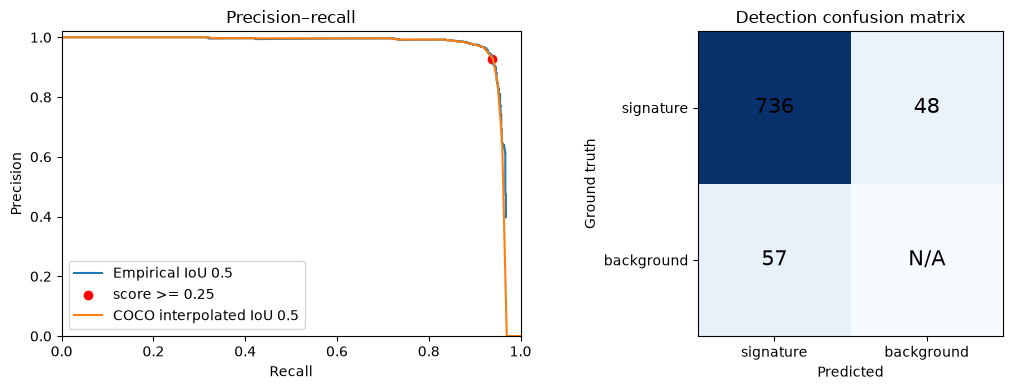

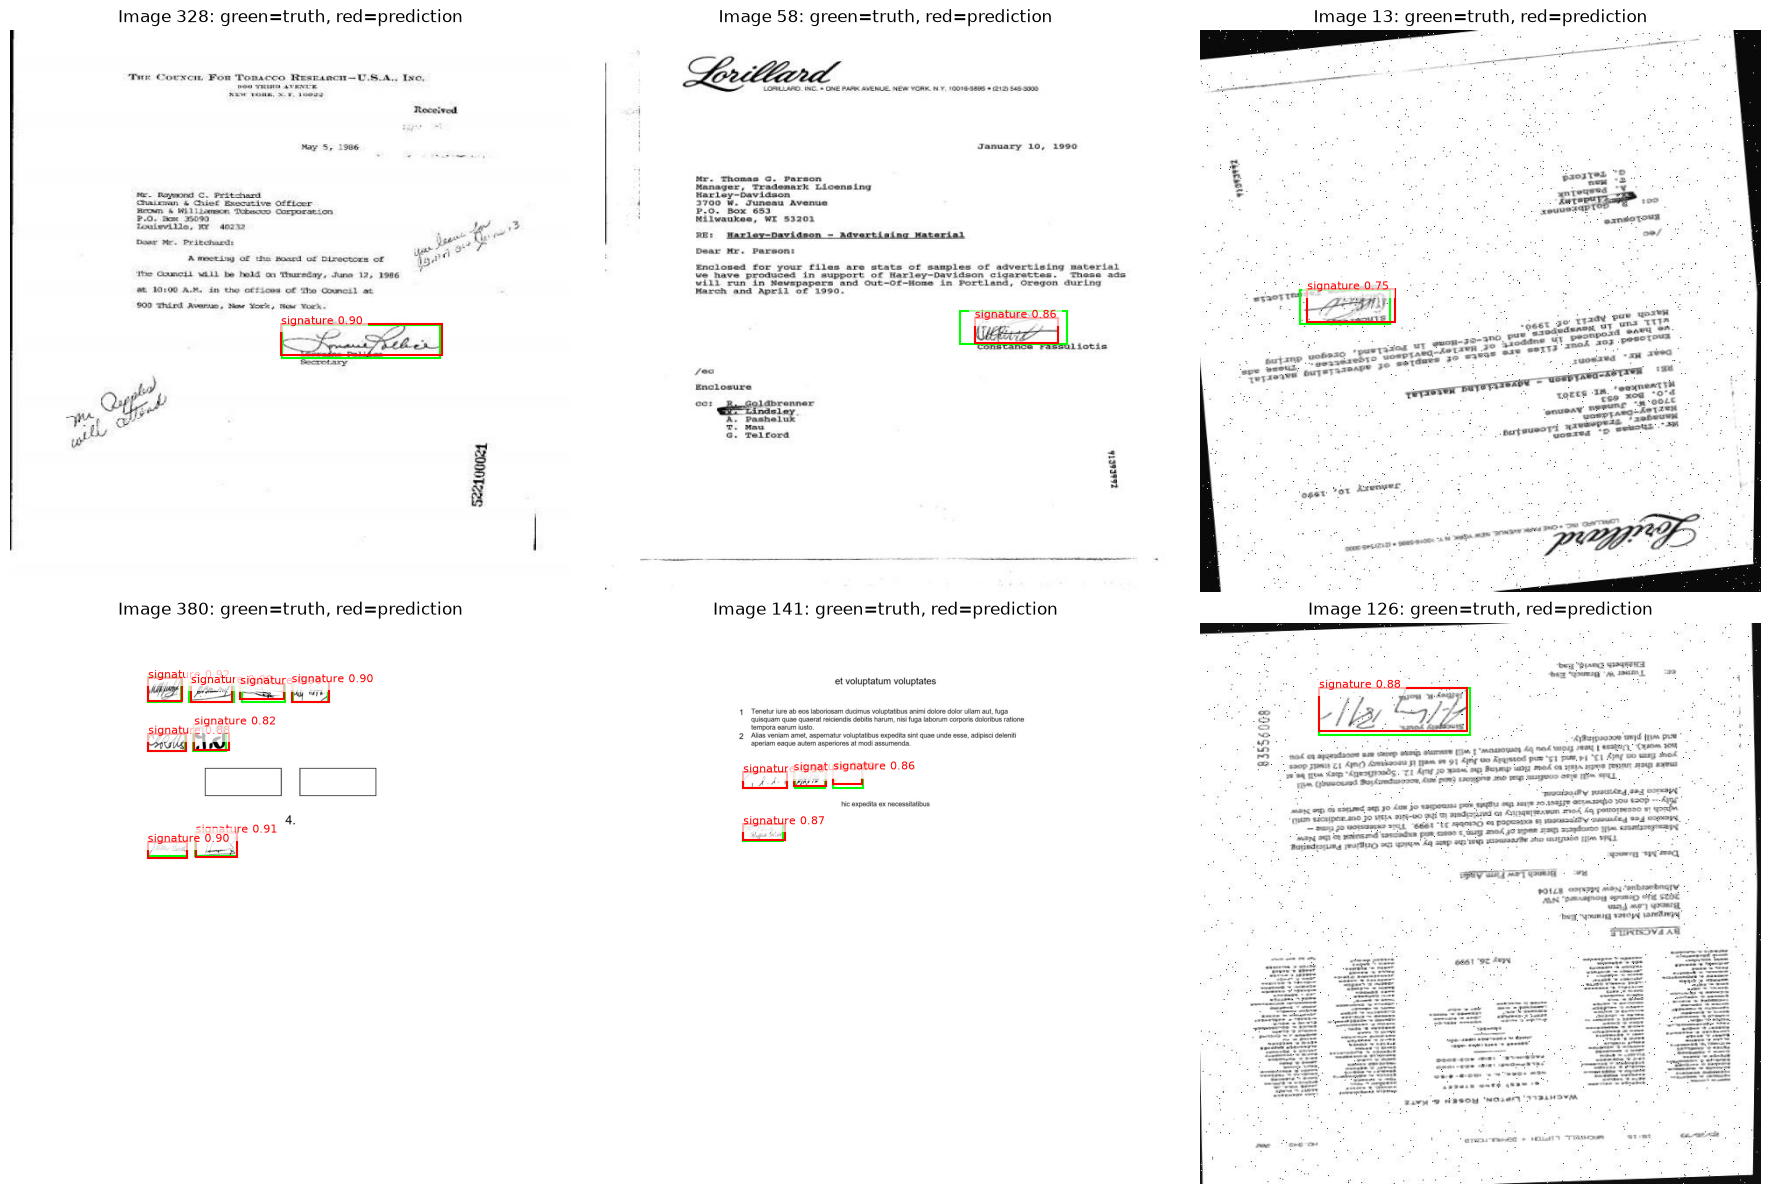

In [29]:
def evaluate_trained_model():
    assert 0 <= EVAL['confidence'] <= 1 and 0 < EVAL['match_iou'] <= 1
    assert EVAL['max_detections'] == 100, 'Keep 100 for standard COCO AP comparability.'
    assert EVAL['confidence'] >= TRAIN['test_conf'], 'Operating threshold must be at least the inference score floor.'
    saved = json.loads(TRAIN_CONFIG_FILE.read_text())['train']
    assert all(saved[k] == TRAIN[k] for k in ('input_size', 'test_conf', 'nms', 'batch_size', 'experiment')), 'Settings changed: regenerate Stage 7 before evaluation.'
    split = EVAL['split']
    assert split in ('val', 'test')
    checkpoint_path = Path(EVAL['checkpoint']) if EVAL['checkpoint'] else OUTPUTS / TRAIN['experiment'] / 'best_ckpt.pth'
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Train first or configure your trained checkpoint: {checkpoint_path}')
    result_dir = REPORTS / f'evaluation_{split}'; result_dir.mkdir(exist_ok=True)
    gt = COCO(str(MERGED / 'annotations' / f'instances_{SPLIT_DIR[split]}.json'))
    predictions = infer_split(checkpoint_path, split)
    write_json(result_dir / 'predictions_coco.json', predictions)
    evaluator = coco_metrics(gt, predictions)
    outcomes, number_gt, gt_boxes = match_detections(gt, predictions, EVAL['match_iou'])
    operating = [row for row in outcomes if row['score'] >= EVAL['confidence']]
    tp = sum(row['tp'] for row in operating); fp = sum(row['fp'] for row in operating); fn = number_gt - tp
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/number_gt if number_gt else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    metrics = dict(split=split, checkpoint=str(checkpoint_path), checkpoint_sha256=sha256_file(checkpoint_path),
                   images=len(gt.getImgIds()), ground_truth_boxes=number_gt,
                   precision=precision, recall=recall, f1=f1, tp=tp, fp=fp, fn=fn,
                   map_50=float(evaluator.stats[1]), map_50_95=float(evaluator.stats[0]),
                   confidence=EVAL['confidence'], match_iou=EVAL['match_iou'],
                   score_floor=TRAIN['test_conf'], max_detections=EVAL['max_detections'])
    metrics.update(input_size=TRAIN['input_size'], nms=TRAIN['nms'],
                   annotation_sha256=sha256_file(MERGED / 'annotations' / f'instances_{SPLIT_DIR[split]}.json'))
    write_json(result_dir / 'metrics.json', metrics)
    print(json.dumps(metrics, indent=2))
    per_image = []
    for image_id in sorted(gt.getImgIds()):
        rows = [row for row in operating if row['image_id'] == image_id]
        per_image.append(dict(image_id=image_id, file_name=gt.imgs[image_id]['file_name'],
            ground_truth=len(gt_boxes[image_id]), tp=sum(r['tp'] for r in rows),
            fp=sum(r['fp'] for r in rows), fn=len(gt_boxes[image_id])-sum(r['tp'] for r in rows)))
    pd.DataFrame(per_image).to_csv(result_dir / 'per_image_counts.csv', index=False)

    # Group equal scores into one PR point, retaining score-ordered matching decisions.
    if outcomes:
        curve = pd.DataFrame(outcomes).groupby('score', sort=True)[['tp', 'fp']].sum().sort_index(ascending=False)
        curve['tp_cumulative'] = curve['tp'].cumsum(); curve['fp_cumulative'] = curve['fp'].cumsum()
        curve['precision'] = curve['tp_cumulative'] / (curve['tp_cumulative'] + curve['fp_cumulative'])
        curve['recall'] = curve['tp_cumulative'] / max(number_gt, 1)
    else:
        curve = pd.DataFrame(columns=['tp', 'fp', 'tp_cumulative', 'fp_cumulative', 'precision', 'recall'])
        curve.index.name = 'score'
    curve.to_csv(result_dir / 'precision_recall_by_score.csv')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].step(curve['recall'], curve['precision'], where='post', label=f"Empirical IoU {EVAL['match_iou']}")
    axes[0].scatter([recall], [precision], color='red', label=f"score >= {EVAL['confidence']}")
    iou50 = int(np.flatnonzero(np.isclose(evaluator.params.iouThrs, 0.5))[0])
    coco_precision = evaluator.eval['precision'][iou50, :, 0, 0, -1]
    valid = coco_precision >= 0
    axes[0].plot(evaluator.params.recThrs[valid], coco_precision[valid], label='COCO interpolated IoU 0.5')
    axes[0].set(xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1.02), title='Precision–recall'); axes[0].legend()
    matrix = np.array([[tp, fn], [fp, 0]], dtype=float)
    axes[1].imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            axes[1].text(column, row, 'N/A' if (row, column)==(1,1) else str(int(matrix[row,column])),
                         ha='center', va='center', fontsize=15, color='black')
    axes[1].set(xticks=[0,1], yticks=[0,1], xticklabels=['signature', 'background'],
                yticklabels=['signature', 'background'], xlabel='Predicted', ylabel='Ground truth', title='Detection confusion matrix')
    fig.tight_layout(); fig.savefig(result_dir / 'precision_recall_confusion.png', dpi=160); plt.show()

    selected = random.Random(SEED).sample(sorted(gt.getImgIds()), min(EVAL['samples'], len(gt.getImgIds())))
    if selected:
        columns = min(3, len(selected)); rows = math.ceil(len(selected)/columns)
        fig, axes = plt.subplots(rows, columns, figsize=(6*columns, 6*rows), squeeze=False)
        by_image = defaultdict(list)
        for prediction in predictions:
            if prediction['score'] >= EVAL['confidence']:
                by_image[prediction['image_id']].append(prediction)
        for ax in axes.flat:
            ax.axis('off')
        for ax, image_id in zip(axes.flat, selected):
            path = MERGED / SPLIT_DIR[split] / gt.imgs[image_id]['file_name']
            with Image.open(path) as image:
                ax.imshow(image)
            for x, y, w, h in gt_boxes[image_id]:
                ax.add_patch(Rectangle((x,y),w,h,fill=False,color='lime',linewidth=1.5))
            for prediction in by_image[image_id]:
                x,y,w,h = prediction['bbox']
                ax.add_patch(Rectangle((x,y),w,h,fill=False,color='red',linewidth=1.5))
                ax.text(x, y, f"signature {prediction['score']:.2f}", color='red', fontsize=8,
                        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
            ax.set_title(f"Image {image_id}: green=truth, red=prediction")
        fig.tight_layout(); fig.savefig(result_dir / 'sample_predictions.png', dpi=150); plt.show()
    return metrics

if RUN_EVALUATION:
    evaluation_metrics = evaluate_trained_model()
else:
    print('Evaluation is disabled. After training, set RUN_EVALUATION=True and execute this cell yourself.')


## Outputs, reruns, and troubleshooting

- Preserve `reports/`, `experiments/`, the source ZIP, original dataset READMEs, and checkpoints with your run. Runtime manifests contain measured counts, removals/repairs, category mappings, exact duplicate choices, split membership, source/weight hashes, and environment versions. No key is written by the notebook's reporting code.
- Run all preparation cells in order after changing source versions, cleaning rules, or groups. Use a fresh project directory for a different dataset snapshot. The manifests control membership; stale image files are never globbed into training. Do not move a checkpoint to a different class/input configuration without checking compatibility.
- To inspect training in TensorBoard, run `%load_ext tensorboard` then `%tensorboard --logdir /content/signature_yolox/outputs` in a new cell, adjusting the path if necessary.
- On CUDA memory errors, reduce batch size first, then input size; set a corresponding total learning rate and regenerate Stage 7. Disable mixed precision only if it causes numeric issues. CPU can prepare data and evaluate slowly; official YOLOX training here needs NVIDIA CUDA.
- For a missing local dataset error, verify `LOCAL_DATASET_BASE` and each source's folder name. On Colab, first make the existing folders available through Drive or a manual upload and point the configuration to that location. No dataset API access is used.
- A schema/category failure, EXIF mismatch, corrupt image, large boundary error, or duplicate-label conflict requires inspecting the raw export and report. The notebook cannot infer missing ground truth reliably. `ACCEPT_QUARANTINE` allows documented exclusions; it cannot bypass structural failures or conflicts.
- Very large/false similarity groups need review of filenames and image pairs. Reduce the pHash radius or refine the family function only with evidence, and supplement missing origins using the manual CSV. A large form-template family can reduce the effective number of independent samples.
- A fresh Colab session may need dependencies reinstalled and data restored. An interrupt stops the training subprocess; only saved epochs can be resumed. Save outputs to durable storage before the runtime expires.

## Primary references

- [Official YOLOX 0.3.0 source and model links](https://github.com/Megvii-BaseDetection/YOLOX/tree/0.3.0), [Tiny experiment](https://github.com/Megvii-BaseDetection/YOLOX/blob/0.3.0/exps/default/yolox_tiny.py), [custom data guide](https://github.com/Megvii-BaseDetection/YOLOX/blob/0.3.0/docs/train_custom_data.md).
- [Official trainer](https://github.com/Megvii-BaseDetection/YOLOX/blob/0.3.0/yolox/core/trainer.py), [base experiment and dataloaders](https://github.com/Megvii-BaseDetection/YOLOX/blob/0.3.0/yolox/exp/yolox_base.py), [COCO adapter](https://github.com/Megvii-BaseDetection/YOLOX/blob/0.3.0/yolox/data/datasets/coco.py), [image transforms](https://github.com/Megvii-BaseDetection/YOLOX/blob/0.3.0/yolox/data/data_augment.py).
- Dataset project links and read-only observations of the existing local COCO exports are in the introduction.
- [COCO evaluation implementation](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py), [PyTorch installation and wheel selection](https://pytorch.org/get-started/locally/).
- [OpenCV ORB feature descriptors](https://docs.opencv.org/4.x/d1/d89/tutorial_py_orb.html) and [feature matching with RANSAC homography](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html), used for candidate verification in Stage 5.

**Revision status:** the local run was interrupted during epoch eight after seven saved epochs. This revision targets 30 total epochs, resumes the existing optimizer/model checkpoint, benchmarks batch sizes only when you execute Stage 7, reuses validated preparation, and reduces validation/checkpoint overhead. No new backup was created for this revision. The assistant has not run the benchmark, training, or evaluation. Saved outputs in unchanged cells and files are from your own runs.
